<p class="lead">A model that only its author can run has a readership of one. This unit takes the ROCK1 predictor built earlier in the course and turns it into something a medicinal chemist in another laboratory can use from a browser: a serialised pipeline with a manifest, an inference function that validates what it is given, an applicability-domain verdict and a conformal interval attached to every prediction, a Streamlit application and a FastAPI endpoint whose complete source is printed and explained here, and a model card that states — in writing, before anyone asks — what the model is for, what it was trained on, how well it does under an honest split, and where it must not be used. The central experiment is the one that justifies all that machinery: what a deployed predictor does when it is handed a molecule from a chemistry it has never seen, and how confidently it does it.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad convierte un modelo en una herramienta utilizable por terceros. Se entrena el predictor de ROCK1 con una partición por andamiajes en tres bloques, se define su dominio de aplicabilidad mediante la distancia de Tanimoto a los vecinos más cercanos y se construye a mano un predictor conformal inductivo, cuyo índice de cuantil se deduce en papel y se confirma con código. Se serializa la tubería con joblib junto a un manifiesto de versiones y sumas de verificación, discutiendo la trampa de compatibilidad de pickle y el papel de ONNX. Se valida la entrada en tiempo de inferencia (saneamiento con RDKit, eliminación de contraiones, control de elementos y tamaño) mostrando cada clase de rechazo. Se escribe una función de predicción que devuelve potencia, intervalo conformal, veredicto de dominio, vecinos más cercanos y atribuciones SHAP, y se mide el fallo más importante de una herramienta desplegada: la extrapolación silenciosa. Se presentan, comentadas línea por línea, una aplicación Streamlit y un punto de acceso FastAPI con sus esquemas de petición y respuesta, una tarjeta de modelo y una tarjeta de datos completas, y las obligaciones de despliegue, registro, versionado, mantenimiento y retirada.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Serialise a trained pipeline safely (joblib, version pinning, input validation) and document it with a model card: intended use, data, metrics, limitations, applicability domain.</li>
<li>Build a small interactive application in which a chemist pastes a SMILES string and obtains a prediction with its uncertainty and an explanation.</li>
<li>Expose the same model as a REST API with schema validation, and know how such an endpoint is tested.</li>
<li>Deploy on a free tier with secrets handled correctly, and accept the maintenance and sunset obligations that deployment creates.</li>
<li>Recognise and prevent silent extrapolation: a confident number returned for a molecule outside the model's domain.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Run every cell in order; the model is retrained here in a few seconds, so nothing is read from another unit. In Colab run <code>!pip install rdkit shap</code> once before the setup cell. A web application and an HTTP server cannot run inside a notebook that must terminate, so the Streamlit and FastAPI code is written out in full, explained line by line, and the function underneath it — the one both of them call — is executed here on real molecules, which is where every number quoted in the text comes from. The applicability domain and the conformal predictor follow <a href="../U17_Uncertainty_AD/index.html">Unit 17</a>, in a compact implementation repeated here so that the notebook stands alone.</p></div>

In [1]:
# Setup. In Google Colab run once:  !pip install rdkit shap
from pathlib import Path
import urllib.request, sys, os, io, json, math, time, hashlib, platform, tempfile, shutil, textwrap
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, rdkit, joblib
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator, Descriptors, Crippen, rdMolDescriptors
from rdkit.Chem.MolStandardize import rdMolStandardize
from sklearn.ensemble import RandomForestRegressor
RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")

SEED = 0
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"
def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest
def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

WORK = Path(tempfile.mkdtemp(prefix="u26_"))
MODEL_VERSION = "1.0.0"
print("python", platform.python_version(), "| scikit-learn", sklearn.__version__,
      "| rdkit", rdkit.__version__, "| joblib", joblib.__version__)
print("artefact folder:", WORK)

python 3.11.15 | scikit-learn 1.9.0 | rdkit 2026.03.4 | joblib 1.5.3
artefact folder: /tmp/u26_zx6v2d0g


## 1. What changes when somebody else can press the button

Up to this unit the model has had one user, who knows how it was built, which compounds it saw, and what its error looks like on new scaffolds. Deployment removes all three. The person who types a SMILES string into a web page sees a number with two decimal places and a clean interface, and has no way of knowing that the molecule they pasted is unlike anything in the training set — unless the tool tells them.

That asymmetry is the whole subject of this unit. Everything built below exists to transmit, through the interface, the three things the author knows and the user does not: how certain the prediction is, whether the molecule is in the region where the model has evidence, and what the model is looking at when it answers.

<div class="box bridge"><h4>Domain context — who uses a published model, and how it goes wrong</h4>
<p>A published QSAR model has three kinds of user. A <strong>medicinal chemist</strong> ranking a handful of synthesis candidates wants one number per molecule and an honest flag; they will not install Python. A <strong>computational colleague</strong> screening a catalogue of 200,000 compounds wants an interface they can call from a script — a REST API or the package itself — and will care about throughput. A <strong>referee or a future student</strong> wants to reproduce a figure, which means the model file, its version and the code that made it. Tools built for the first group but used by the second are the standard failure: a web form that silently truncates, times out, or — worst — happily returns predictions for compounds far outside the chemistry it was trained on. Published predictors of solubility, toxicity and potency are routinely used on molecules their authors never imagined, and because a regression model always returns <em>something</em>, nothing in the output says so. There is also a legal dimension: when users upload their own structures, those structures are confidential pre-publication intellectual property, and in a European or Chilean institutional context uploading a collaborator's unpublished compound to a third-party server can breach both an agreement and a data-protection policy. The group's rule is that a hosted tool states what it stores, stores nothing by default, and offers a local option for anything confidential.</p></div>

Models published with a usable interface are also the ones that get used: the deep-learning antibiotic screen that produced halicin is cited as much for its shared model and predictions as for the molecule<sup class="c"><a href="#r28">[28]</a></sup>. The literature on deploying machine learning is equally blunt about where projects fail: not in the modelling, but in everything around it — data validation at inference, versioning, monitoring and the slow drift of the environment<sup class="c"><a href="#r4">[4]</a><a href="#r5">[5]</a></sup>, which is why best-practice guidance for chemistry now treats deployment and reporting as part of the method<sup class="c"><a href="#r7">[7]</a></sup>. The reporting instruments that make a model usable by others — the **model card**<sup class="c"><a href="#r1">[1]</a></sup> and the **dataset card** or datasheet<sup class="c"><a href="#r2">[2]</a></sup> — were introduced precisely because the information that prevents misuse is known at training time and lost by publication time.

## 2. The thing being shipped

A deployed predictor is not a model object. It is a contract: given a structure, return a potency estimate, an interval that covers the truth at a stated rate, a verdict on whether the molecule lies in the model's domain, and enough explanation for a chemist to decide whether to believe it. The model is a random forest<sup class="c"><a href="#r24">[24]</a></sup> in scikit-learn<sup class="c"><a href="#r25">[25]</a></sup> trained on the curated ChEMBL table of Unit 6<sup class="c"><a href="#r14">[14]</a></sup>, split by scaffold rather than at random because a random split rewards memorisation of chemotypes and overstates what a model will do on new chemistry<sup class="c"><a href="#r21">[21]</a><a href="#r22">[22]</a></sup>. The next two cells build all four parts on a three-way scaffold split — training, calibration (for the conformal intervals), and test (never touched until the evaluation).

In [2]:
# Data, features, and a three-way split by Bemis-Murcko scaffold.
df = load_data("rock1_chembl_curated.csv")
exact = df.loc[~df["censored"]].reset_index(drop=True)
DESC = ["MolWt", "MolLogP", "TPSA", "HBD", "HBA", "RotB",
        "AromaticRings", "RingCount", "HeavyAtoms", "FractionCSP3", "QED"]
GEN = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

mols = [Chem.MolFromSmiles(s) for s in exact["std_smiles"]]
fps = [GEN.GetFingerprint(m) for m in mols]
Xfp = np.array([GEN.GetFingerprintAsNumPy(m) for m in mols], dtype=np.float32)
X = np.hstack([Xfp, exact[DESC].to_numpy(float)])
y = exact["pActivity"].to_numpy()
scaffolds = exact["scaffold_smiles"].to_numpy()

def scaffold_split(scaf, fractions=(0.6, 0.2)):
    '''Largest scaffold families to training, then calibration, rarest to test. Deterministic.'''
    groups = pd.Series(scaf).groupby(scaf).groups
    order = sorted(groups.values(), key=lambda g: (-len(g), str(scaf[g[0]])))
    train, calib, test = [], [], []
    n_tr, n_ca = int(fractions[0] * len(scaf)), int(fractions[1] * len(scaf))
    for g in order:
        (train if len(train) < n_tr else calib if len(calib) < n_ca else test).extend(list(g))
    return np.array(train), np.array(calib), np.array(test)

TR, CA, TE = scaffold_split(scaffolds)
print(f"{len(exact)} compounds with exact measurements, {exact['scaffold_smiles'].nunique()} scaffolds")
print(f"train {len(TR)} | calibration {len(CA)} | test {len(TE)}; "
      f"scaffolds shared between train and test: {len(set(scaffolds[TR]) & set(scaffolds[TE]))}")
print(f"target: pActivity, mean {y[TR].mean():.2f}, sd {y[TR].std():.2f} on the training set")

2764 compounds with exact measurements, 1218 scaffolds
train 1658 | calibration 552 | test 554; scaffolds shared between train and test: 0
target: pActivity, mean 6.68, sd 1.10 on the training set


In [3]:
# The model, the conformal calibration and the applicability domain: the four parts of the contract.
t0 = time.time()
model = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=4).fit(X[TR], y[TR])
pred_ca, pred_te = model.predict(X[CA]), model.predict(X[TE])
rmse_te = float(np.sqrt(np.mean((pred_te - y[TE]) ** 2)))
mae_te = float(np.mean(np.abs(pred_te - y[TE])))
r2_te = float(1 - np.sum((pred_te - y[TE]) ** 2) / np.sum((y[TE] - y[TE].mean()) ** 2))

# inductive conformal prediction: the quantile of the calibration residuals
resid_ca = np.abs(pred_ca - y[CA])
def conformal_q(residuals, confidence):
    '''The (n+1)(1-eps)/n empirical quantile of the calibration residuals.'''
    n = len(residuals)
    k = math.ceil((n + 1) * confidence)
    return float(np.sort(residuals)[min(k, n) - 1]), k, n
Q90, K90, N_CA = conformal_q(resid_ca, 0.90)

# applicability domain: mean Tanimoto distance to the k nearest training compounds
TRAIN_FPS = [fps[i] for i in TR]
def ad_distance(fp, train_fps=None, k=5):
    '''1 - mean Tanimoto similarity to the k most similar training compounds.'''
    sims = np.array(DataStructs.BulkTanimotoSimilarity(fp, train_fps or TRAIN_FPS))
    return float(1.0 - np.mean(np.sort(sims)[-k:]))
rng = np.random.default_rng(SEED)
probe = rng.choice(TR, 600, replace=False)
d_train = np.array([ad_distance(fps[i], [fps[j] for j in TR if j != i][:2000]) for i in probe])
AD_THRESHOLD = float(np.quantile(d_train, 0.95))
d_test = np.array([ad_distance(fps[i]) for i in TE])
inside = d_test <= AD_THRESHOLD

print(f"fitted in {time.time()-t0:.1f} s")
print(f"scaffold test set: RMSE {rmse_te:.3f}, MAE {mae_te:.3f}, R2 {r2_te:.3f} (n = {len(TE)})")
print(f"conformal 90%: quantile index k = {K90} of n = {N_CA} calibration residuals -> "
      f"half-width {Q90:.3f} log units")
print(f"applicability-domain threshold (95th percentile of training distances): {AD_THRESHOLD:.3f}")
print(f"test compounds inside the domain: {inside.sum()} of {len(TE)} ({100*inside.mean():.0f}%)")

fitted in 5.3 s
scaffold test set: RMSE 0.895, MAE 0.691, R2 0.251 (n = 554)
conformal 90%: quantile index k = 498 of n = 552 calibration residuals -> half-width 1.400 log units
applicability-domain threshold (95th percentile of training distances): 0.490
test compounds inside the domain: 253 of 554 (46%)


Before going further, the conformal quantile deserves to be worked out by hand, because it is the one place in this pipeline where an off-by-one error silently costs coverage. Inductive conformal prediction<sup class="c"><a href="#r17">[17]</a><a href="#r18">[18]</a></sup> is the standard way of attaching a guaranteed error rate to a QSAR prediction, and has been proposed as a transparent replacement for ad-hoc applicability-domain rules<sup class="c"><a href="#r15">[15]</a><a href="#r16">[16]</a></sup>.

With $n$ calibration residuals and a target confidence $1-\varepsilon = 0.90$, the index to take is

$$k = \lceil (n+1)(1-\varepsilon) \rceil,$$

and the interval half-width is the $k$-th smallest residual. The $+1$ is the test compound itself: validity comes from the rank of its residual among the $n+1$ residuals being uniform under exchangeability.

| quantity | value |
|---|---|
| calibration compounds $n$ | 552 |
| confidence $1-\varepsilon$ | 0.90 |
| $(n+1)(1-\varepsilon)$ | $553 \times 0.9 = 497.7$ |
| $k = \lceil 497.7 \rceil$ | 498 |
| half-width | the 498th smallest of the 552 sorted residuals |

Two consequences follow immediately from that formula. The index cannot exceed $n$, so $n \geq 1/\varepsilon - 1$: with fewer than 19 calibration points a 95 % interval is impossible, and the honest response is to report a lower confidence. And the quantile must come from data the model never saw — fitting it on the training residuals gives an interval that is far too narrow, because a random forest fits its training data almost perfectly.

The cell below checks the hand calculation and measures the empirical coverage at three confidence levels.

In [4]:
# Check the hand-worked quantile index, then measure coverage at three confidence levels.
n_cal = len(resid_ca)
k_hand = math.ceil((n_cal + 1) * 0.90)
print(f"hand calculation: n = {n_cal}, (n+1)(1-eps) = {(n_cal+1)*0.9:.1f}, k = {k_hand}; "
      f"code gave k = {K90} -> {'agree' if k_hand == K90 else 'MISMATCH'}")

rows = []
err_te = np.abs(pred_te - y[TE])
for confidence in (0.80, 0.90, 0.95):
    q, k, _ = conformal_q(resid_ca, confidence)
    rows.append(dict(confidence=confidence, k=k, half_width=round(q, 3),
                     empirical_all=round(float(np.mean(err_te <= q)), 3),
                     empirical_inside_AD=round(float(np.mean(err_te[inside] <= q)), 3),
                     empirical_outside_AD=round(float(np.mean(err_te[~inside] <= q)), 3)))
coverage = pd.DataFrame(rows)
print(coverage.to_string(index=False))
print("\nnominal coverage is the 'confidence' column; the guarantee assumes calibration and test")
print("compounds are exchangeable, which a scaffold split deliberately breaks")

hand calculation: n = 552, (n+1)(1-eps) = 497.7, k = 498; code gave k = 498 -> agree
 confidence   k  half_width  empirical_all  empirical_inside_AD  empirical_outside_AD
       0.80 443       1.122          0.791                0.806                 0.777
       0.90 498       1.400          0.875                0.870                 0.880
       0.95 526       1.663          0.926                0.909                 0.940

nominal coverage is the 'confidence' column; the guarantee assumes calibration and test
compounds are exchangeable, which a scaffold split deliberately breaks


The coverage table is the honest version of "the model predicts potency to within one log unit". Under a scaffold split the empirical coverage falls a little short of nominal at every confidence level — the exchangeability assumption behind the conformal guarantee is violated by construction, exactly as Unit 17 showed — and the two conditional columns say something less comfortable: the shortfall is not concentrated in the compounds the applicability domain flags, which are covered at much the same rate as the rest. The flag is therefore not a refinement of the interval here. Its value lies elsewhere, and Section 6 measures where.

## 3. Serialising the pipeline: joblib, versions and hashes

A fitted scikit-learn model is a Python object graph, and `joblib.dump` writes it with pickle, which stores *references to classes by name*. Nothing in the file describes the library that produced it. Load it with a different scikit-learn version and the result is one of three things: it works; it raises an exception; or — the dangerous one — it loads and behaves differently, because an attribute the new version expects is missing or has changed meaning. Pickle also executes code on load, so a model file from an untrusted source is a security problem, not merely a compatibility one.

The group's practice is therefore to write three files, never one: the model, a manifest describing the environment and the inputs, and the fingerprint/domain parameters needed at inference. The manifest is what turns a binary blob into a scientific artefact.

In [5]:
# Save the artefact: model, manifest with versions and hashes, and the inference parameters.
model_path = WORK / f"rock1_rf_v{MODEL_VERSION}.joblib"
joblib.dump({"model": model, "descriptors": DESC, "fp_radius": 2, "fp_bits": 2048,
             "ad_threshold": AD_THRESHOLD, "conformal": {str(c): conformal_q(resid_ca, c)[0]
                                                         for c in (0.80, 0.90, 0.95)},
             "train_fingerprints": [fp.ToBitString() for fp in TRAIN_FPS],
             "train_pActivity": y[TR].tolist(),
             "train_smiles": exact.loc[TR, "std_smiles"].tolist()},
            model_path, compress=3)

def sha256(path, limit=None):
    data = Path(path).read_bytes()
    return hashlib.sha256(data if limit is None else data[:limit]).hexdigest()

manifest = {
    "name": "rock1-potency-rf", "version": MODEL_VERSION,
    "created": "2026-10-18", "task": "regression of pActivity (-log10 M) for human ROCK1",
    "training_data": {"file": "rock1_chembl_curated.csv", "source": "ChEMBL 37, CHEMBL3231",
                      "sha256": sha256(data_path('rock1_chembl_curated.csv'))[:32],
                      "n_train": int(len(TR)), "n_calibration": int(len(CA)), "n_test": int(len(TE)),
                      "split": "Bemis-Murcko scaffold, deterministic"},
    "features": {"fingerprint": "Morgan radius 2, 2048 bits", "descriptors": DESC,
                 "n_features": int(X.shape[1])},
    "hyperparameters": {"n_estimators": 300, "random_state": SEED, "others": "scikit-learn defaults"},
    "metrics_scaffold_test": {"RMSE": round(rmse_te, 3), "MAE": round(mae_te, 3), "R2": round(r2_te, 3)},
    "environment": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                    "rdkit": rdkit.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
    "artefact": {"file": model_path.name, "sha256": sha256(model_path)[:32],
                 "size_mb": round(model_path.stat().st_size / 1e6, 2)},
    "licence": {"code": "MIT", "model_and_data": "CC BY-SA 3.0 (inherited from ChEMBL)"},
}
(WORK / "manifest.json").write_text(json.dumps(manifest, indent=1))
print(json.dumps(manifest, indent=1)[:1500], "...")
print(f"\nmodel file {model_path.name}: {manifest['artefact']['size_mb']} MB, "
      f"sha256 {manifest['artefact']['sha256']}")

{
 "name": "rock1-potency-rf",
 "version": "1.0.0",
 "created": "2026-10-18",
 "task": "regression of pActivity (-log10 M) for human ROCK1",
 "training_data": {
  "file": "rock1_chembl_curated.csv",
  "source": "ChEMBL 37, CHEMBL3231",
  "sha256": "765ab0cf633b4dd26a9be200f21c7972",
  "n_train": 1658,
  "n_calibration": 552,
  "n_test": 554,
  "split": "Bemis-Murcko scaffold, deterministic"
 },
 "features": {
  "fingerprint": "Morgan radius 2, 2048 bits",
  "descriptors": [
   "MolWt",
   "MolLogP",
   "TPSA",
   "HBD",
   "HBA",
   "RotB",
   "AromaticRings",
   "RingCount",
   "HeavyAtoms",
   "FractionCSP3",
   "QED"
  ],
  "n_features": 2059
 },
 "hyperparameters": {
  "n_estimators": 300,
  "random_state": 0,
  "others": "scikit-learn defaults"
 },
 "metrics_scaffold_test": {
  "RMSE": 0.895,
  "MAE": 0.691,
  "R2": 0.251
 },
 "environment": {
  "python": "3.11.15",
  "scikit-learn": "1.9.0",
  "rdkit": "2026.03.4",
  "numpy": "2.4.6",
  "joblib": "1.5.3"
 },
 "artefact": {
  "fil

In [6]:
# Load it back the way a server would, and refuse to serve it if the environment does not match.
bundle = joblib.load(model_path)
check = model.predict(X[TE[:5]])
again = bundle["model"].predict(X[TE[:5]])
print("round trip identical:", bool(np.allclose(check, again)),
      f"(max difference {np.abs(check-again).max():.2e})")

def environment_check(manifest, strict=False):
    '''Compare the running environment with the one recorded when the model was fitted.'''
    current = {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
               "rdkit": rdkit.__version__, "numpy": np.__version__, "joblib": joblib.__version__}
    problems = [f"{k}: model built with {v}, running {current[k]}"
                for k, v in manifest["environment"].items() if current.get(k) != v]
    if problems and strict:
        raise RuntimeError("environment mismatch: " + "; ".join(problems))
    return problems

print("environment check now:", environment_check(manifest) or "identical to the recorded environment")
pretend = dict(manifest, environment=dict(manifest["environment"], **{"scikit-learn": "1.3.0"}))
print("environment check against a pretend older build:", environment_check(pretend))
try:
    environment_check(pretend, strict=True)
except RuntimeError as error:
    print("strict mode refuses to serve:", str(error)[:90], "...")

round trip identical: True (max difference 1.78e-15)
environment check now: identical to the recorded environment
environment check against a pretend older build: ['scikit-learn: model built with 1.3.0, running 1.9.0']
strict mode refuses to serve: environment mismatch: scikit-learn: model built with 1.3.0, running 1.9.0 ...


That check costs four lines and prevents the quietest class of production bug: a server that keeps answering after an unattended dependency upgrade changed the meaning of the model. The group's rule is that the serving environment is pinned (a lock file or a container image, as in Unit 25), the manifest is compared at start-up, and a mismatch is a refusal in production and a warning in development.

**ONNX** is the alternative worth knowing about. Converting a scikit-learn pipeline to the ONNX graph format with `skl2onnx` produces a file that contains the computation rather than Python objects: it loads without scikit-learn, runs in any language with an ONNX runtime, and does not execute arbitrary code. The costs are real — not every estimator or custom transformer converts, the numerical results can differ in the last decimals, and the chemistry (RDKit featurisation) stays outside the graph — so the group uses joblib plus a pinned container for internal tools, and considers ONNX when a model must be embedded in software the group does not control.

## 4. Validating the input before the model sees it

The featurisation in this notebook assumed a valid, standardised structure. A deployed tool receives whatever a user types: a name instead of a SMILES, a salt, a mixture, an inorganic species, a protein-sized molecule, an empty string, ten thousand characters of pasted spreadsheet. Every one of those must produce a clear refusal rather than a prediction or a traceback.

In [7]:
# Input validation: one function, every rejection class named.
ALLOWED_ELEMENTS = {"H", "B", "C", "N", "O", "F", "Si", "P", "S", "Cl", "Br", "I"}
MAX_HEAVY, MIN_HEAVY, MAX_LENGTH = 70, 3, 600
_normalizer, _uncharger = rdMolStandardize.Normalizer(), rdMolStandardize.Uncharger()
_largest = rdMolStandardize.LargestFragmentChooser()

def validate_and_standardise(smiles):
    '''Return (mol, standard_smiles, note) or (None, None, reason) - never raise, never guess.'''
    if not isinstance(smiles, str) or not smiles.strip():
        return None, None, "empty input"
    smiles = smiles.strip()
    if len(smiles) > MAX_LENGTH:
        return None, None, f"input longer than {MAX_LENGTH} characters"
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or mol.GetNumAtoms() == 0:
        return None, None, "not a parsable SMILES string"
    note = ""
    if "." in Chem.MolToSmiles(mol):
        note = "mixture or salt: largest fragment kept"
    try:
        mol = _uncharger.uncharge(_largest.choose(_normalizer.normalize(mol)))
        Chem.SanitizeMol(mol)
    except Exception:
        return None, None, "structure could not be standardised"
    elements = {a.GetSymbol() for a in mol.GetAtoms()}
    if not elements <= ALLOWED_ELEMENTS:
        return None, None, f"unsupported elements: {sorted(elements - ALLOWED_ELEMENTS)}"
    heavy = mol.GetNumHeavyAtoms()
    if not MIN_HEAVY <= heavy <= MAX_HEAVY:
        return None, None, f"{heavy} heavy atoms, outside the supported range {MIN_HEAVY}-{MAX_HEAVY}"
    return mol, Chem.MolToSmiles(mol), note

CASES = [("CC(C)c1ccccc1NC(=O)c1ccc(-c2cn[nH]c2)cc1", "a plausible kinase inhibitor"),
         ("CC(=O)[O-].[Na+]", "a salt"), ("fasudil", "a name, not a SMILES"),
         ("c1ccccc1C(", "malformed SMILES"), ("[Pt](Cl)(Cl)(N)N", "an inorganic complex"),
         ("CCO", "too small"), ("C" * 120, "a very large aliphatic chain"), ("   ", "blank input")]
for raw, label in CASES:
    mol, std, note = validate_and_standardise(raw)
    status = "accepted" if mol is not None else "REJECTED"
    detail = (std[:42] + ("  [" + note + "]" if note else "")) if mol is not None else note
    print(f"{label:<28} {status:<9} {detail}")

a plausible kinase inhibitor accepted  CC(C)c1ccccc1NC(=O)c1ccc(-c2cn[nH]c2)cc1
a salt                       accepted  CC(=O)O  [mixture or salt: largest fragment kept]
a name, not a SMILES         REJECTED  not a parsable SMILES string
malformed SMILES             REJECTED  not a parsable SMILES string
an inorganic complex         REJECTED  unsupported elements: ['Pt']
too small                    accepted  CCO
a very large aliphatic chain REJECTED  120 heavy atoms, outside the supported range 3-70
blank input                  REJECTED  empty input


Three design decisions in that function are worth defending, because each corresponds to a complaint the group has received about somebody else's tool.

**It never raises.** Every failure returns a reason string that the interface can show. A traceback on a web page is both unhelpful and an information leak.

**It standardises explicitly and says so.** When a salt is submitted, the tool keeps the largest fragment, predicts for the parent, and reports that it did — silently predicting for something other than what the user typed is the shortest route to a wrong decision in a laboratory.

These bounds, with the distance measure defined above, are the two layers of applicability domain the QSAR literature distinguishes: a coarse range box and a fine distance-to-training-set criterion<sup class="c"><a href="#r19">[19]</a><a href="#r20">[20]</a></sup>.

**It bounds the input.** Element and size limits are not pedantry: the training set contains small organic molecules with a dozen common elements, so a platinum complex or a 120-carbon chain is outside the chemistry the model saw, and refusing is more useful than extrapolating. These bounds are a *coarse* applicability domain; the fine one, measured in the model's own representation, comes next.

## 5. The prediction function the interfaces call

Both the application and the API are thin wrappers around a single function. Writing it once, here, is what keeps the two interfaces consistent — and what makes the contract testable.

In [8]:
# One function, four answers: prediction, interval, domain verdict, explanation.
import shap
EXPLAINER = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent")
FEATURE_NAMES = [f"bit_{i}" for i in range(2048)] + DESC
TRAIN_SMILES = exact.loc[TR, "std_smiles"].tolist()
TRAIN_Y = y[TR]

def featurise(mol):
    '''Morgan fingerprint plus the descriptor block, in the order the model was trained on.'''
    fp = GEN.GetFingerprint(mol)
    arr = GEN.GetFingerprintAsNumPy(mol).astype(np.float32)
    desc = np.array([Descriptors.MolWt(mol), Crippen.MolLogP(mol), rdMolDescriptors.CalcTPSA(mol),
                     rdMolDescriptors.CalcNumHBD(mol), rdMolDescriptors.CalcNumHBA(mol),
                     rdMolDescriptors.CalcNumRotatableBonds(mol),
                     rdMolDescriptors.CalcNumAromaticRings(mol), rdMolDescriptors.CalcNumRings(mol),
                     float(mol.GetNumHeavyAtoms()), rdMolDescriptors.CalcFractionCSP3(mol),
                     Descriptors.qed(mol)], dtype=float)
    return fp, np.hstack([arr, desc]).reshape(1, -1)

def predict_compound(smiles, confidence=0.90, n_neighbours=3, explain=True):
    '''The full prediction contract for one structure. Returns a JSON-serialisable dictionary.'''
    mol, std_smiles, note = validate_and_standardise(smiles)
    if mol is None:
        return {"status": "rejected", "reason": note, "input": smiles,
                "model_version": MODEL_VERSION}
    fp, features = featurise(mol)
    value = float(model.predict(features)[0])
    half = float(bundle["conformal"][str(confidence)])
    distance = ad_distance(fp)
    sims = np.array(DataStructs.BulkTanimotoSimilarity(fp, TRAIN_FPS))
    order = np.argsort(-sims)[:n_neighbours]
    out = {
        "status": "ok", "model_version": MODEL_VERSION, "input": smiles,
        "standard_smiles": std_smiles, "note": note,
        "pActivity": round(value, 2),
        "interval": [round(value - half, 2), round(value + half, 2)],
        "confidence": confidence,
        "IC50_nM_estimate": round(10 ** (9 - value), 1),
        "applicability": {"distance": round(distance, 3), "threshold": round(AD_THRESHOLD, 3),
                          "in_domain": bool(distance <= AD_THRESHOLD)},
        "nearest_training_compounds": [
            {"smiles": TRAIN_SMILES[i], "tanimoto": round(float(sims[i]), 3),
             "measured_pActivity": round(float(TRAIN_Y[i]), 2)} for i in order],
    }
    if explain:
        contributions = EXPLAINER.shap_values(features, check_additivity=False)[0]
        top = np.argsort(-np.abs(contributions))[:5]
        out["top_features"] = [{"feature": FEATURE_NAMES[i],
                                "contribution": round(float(contributions[i]), 3)} for i in top]
    return out

demo = predict_compound("CC(C)c1ccccc1NC(=O)c1ccc(-c2cn[nH]c2)cc1")
print(json.dumps(demo, indent=1)[:1200], "...")
print("\nrejected input:", json.dumps(predict_compound("fasudil"), indent=None))

{
 "status": "ok",
 "model_version": "1.0.0",
 "input": "CC(C)c1ccccc1NC(=O)c1ccc(-c2cn[nH]c2)cc1",
 "standard_smiles": "CC(C)c1ccccc1NC(=O)c1ccc(-c2cn[nH]c2)cc1",
 "note": "",
 "pActivity": 7.09,
 "interval": [
  5.69,
  8.49
 ],
 "confidence": 0.9,
 "IC50_nM_estimate": 81.5,
 "applicability": {
  "distance": 0.518,
  "threshold": 0.49,
  "in_domain": false
 },
 "nearest_training_compounds": [
  {
   "smiles": "COc1cc(C(=O)NCc2ccccc2C(C)C)ccc1-c1cn[nH]c1",
   "tanimoto": 0.5,
   "measured_pActivity": 6.69
  },
  {
   "smiles": "COc1cc(C(=O)N[C@@H](C)c2ccccc2OC)ccc1-c1cn[nH]c1",
   "tanimoto": 0.492,
   "measured_pActivity": 7.14
  },
  {
   "smiles": "CNC(C(=O)Nc1ccc(-c2cn[nH]c2)cc1)c1ccccc1OC",
   "tanimoto": 0.483,
   "measured_pActivity": 7.92
  }
 ],
 "top_features": [
  {
   "feature": "bit_671",
   "contribution": 0.597
  },
  {
   "feature": "bit_1536",
   "contribution": -0.058
  },
  {
   "feature": "bit_1019",
   "contribution": -0.051
  },
  {
   "feature": "bit_837",
   "c

single call with SHAP: 296 ms | without: 28 ms
100 compounds: 2.8 s total -> a 10,000-compound list would take about 4.7 min through this interface
conclusion: a web form is fine, a catalogue screen must use the package, not the API


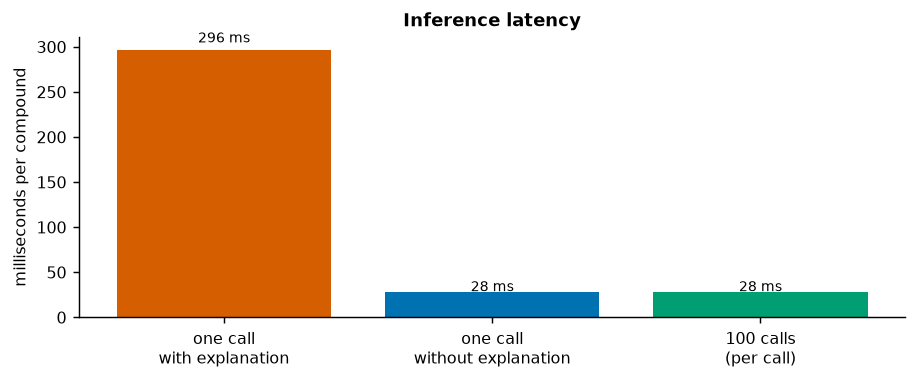

In [9]:
# How long does one prediction take, and how long does a batch of a hundred take?
one = time.perf_counter()
_ = predict_compound(TRAIN_SMILES[0])
t_one = time.perf_counter() - one
start = time.perf_counter()
for s in exact.loc[TE[:100], "std_smiles"]:
    predict_compound(s, explain=False)
t_batch = time.perf_counter() - start

fig, ax = plt.subplots(figsize=(8.2, 2.8))
labels = ["one call\nwith explanation", "one call\nwithout explanation", "100 calls\n(per call)"]
values = [1e3 * t_one, 1e3 * t_batch / 100, 1e3 * t_batch / 100]
bars = ax.bar(labels, values, color=["#D55E00", "#0072B2", "#009E73"])
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width()/2, v * 1.03, f"{v:.0f} ms", ha="center", fontsize=8)
ax.set_ylabel("milliseconds per compound"); ax.set_title("Inference latency")
plt.show()
print(f"single call with SHAP: {1e3*t_one:.0f} ms | without: {1e3*t_batch/100:.0f} ms")
print(f"100 compounds: {t_batch:.1f} s total -> a 10,000-compound list would take about "
      f"{100*t_batch/60:.1f} min through this interface")
print("conclusion: a web form is fine, a catalogue screen must use the package, not the API")

<p class="caption"><b>Figure 1.</b> Latency of the prediction contract. The explanation dominates a single call, which is why it is optional in the function signature and switched off for batches. The projection at the bottom is the one that decides interface design: a form answering one molecule at a time is comfortable, and a colleague who wants to score a catalogue should be given the package or a batch endpoint rather than a loop over single requests.</p>

interval half-width 1.40 log units; the measured value lies inside the interval for 83% of these 30 compounds
of the 30, 15 are inside the applicability domain and 15 outside


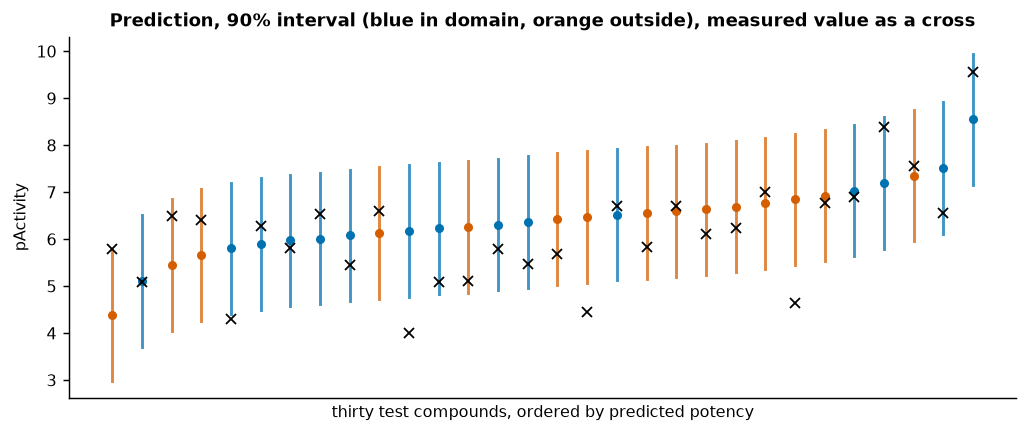

In [10]:
# Thirty test compounds as the user would receive them: estimate, interval, domain flag.
shown = np.argsort(pred_te)[np.linspace(0, len(TE) - 1, 30).astype(int)]
fig, ax = plt.subplots(figsize=(9.4, 3.6))
for j, i in enumerate(shown):
    colour = "#0072B2" if inside[i] else "#D55E00"
    ax.plot([j, j], [pred_te[i] - Q90, pred_te[i] + Q90], color=colour, lw=1.6, alpha=0.75)
    ax.plot(j, pred_te[i], "o", color=colour, ms=4)
    ax.plot(j, y[TE][i], "x", color="black", ms=5)
covered = float(np.mean(np.abs(pred_te[shown] - y[TE][shown]) <= Q90))
ax.set_xticks([]); ax.set_xlabel("thirty test compounds, ordered by predicted potency")
ax.set_ylabel("pActivity")
ax.set_title("Prediction, 90% interval (blue in domain, orange outside), measured value as a cross")
plt.show()
print(f"interval half-width {Q90:.2f} log units; the measured value lies inside the interval for "
      f"{covered:.0%} of these 30 compounds")
print(f"of the 30, {int(inside[shown].sum())} are inside the applicability domain and "
      f"{int((~inside[shown]).sum())} outside")

<p class="caption"><b>Figure 2.</b> Thirty compounds of the scaffold-split test set as the deployed tool would report them: the point estimate, the 90 % conformal interval, and the measured value as a cross, with colour giving the applicability-domain verdict. The intervals are wide — close to two log units in total — which is the honest consequence of calibrating on compounds whose scaffolds the model has never seen, and the crosses falling outside them are the coverage shortfall quantified in the table above.</p>

## 6. The failure that matters: silent extrapolation

Now the experiment. A regression model always returns a number. Ask a random forest trained on ROCK1 inhibitors about a sugar, a peptide fragment or a dye and it will answer with the same two decimal places it uses for a kinase inhibitor — because a forest averages the leaves its input falls into, and an unfamiliar molecule simply lands in leaves belonging to the training distribution. The prediction is not wrong by a little; it is uninformative, and it looks exactly like an informative one.

The cell below asks the deployed function about four groups: test compounds inside the applicability domain, test compounds outside it, property-matched decoys from the screening library (molecules measured against unrelated targets, with maximum Tanimoto similarity to any ROCK1 ligand below 0.35), and a handful of molecules from chemistry the model has certainly never seen — table sugar, caffeine, a tripeptide, a fatty acid, aspirin and a dye.

In [11]:
# What does the deployed model say about molecules it has never seen?
decoys = (load_data("screening_library.csv")
          .query("label == 0").sample(120, random_state=SEED)["std_smiles"].tolist())
EXOTIC = {
    "sucrose": "OC[C@H]1O[C@@](CO)(O[C@H]2O[C@H](CO)[C@@H](O)[C@H](O)[C@H]2O)[C@@H](O)[C@@H]1O",
    "caffeine": "Cn1c(=O)c2c(ncn2C)n(C)c1=O",
    "glycine trimer": "NCC(=O)NCC(=O)NCC(=O)O",
    "palmitic acid": "CCCCCCCCCCCCCCCC(=O)O",
    "aspirin": "CC(=O)Oc1ccccc1C(=O)O",
    "indigo dye": "O=C1Nc2ccccc2C1=C1C(=O)Nc2ccccc21",
}
groups = {}
groups["test, in domain"] = [predict_compound(s, explain=False)
                             for s in exact.loc[TE[inside], "std_smiles"][:120]]
groups["test, outside domain"] = [predict_compound(s, explain=False)
                                  for s in exact.loc[TE[~inside], "std_smiles"][:120]]
groups["screening decoys"] = [predict_compound(s, explain=False) for s in decoys]
groups["other chemistry"] = [predict_compound(s, explain=False) for s in EXOTIC.values()]

summary = []
for name, results in groups.items():
    ok = [r for r in results if r["status"] == "ok"]
    preds = np.array([r["pActivity"] for r in ok])
    dists = np.array([r["applicability"]["distance"] for r in ok])
    summary.append(dict(group=name, n=len(ok),
                        mean_prediction=round(float(preds.mean()), 2),
                        sd_prediction=round(float(preds.std()), 2),
                        mean_AD_distance=round(float(dists.mean()), 3),
                        flagged_outside=f"{100*np.mean(dists > AD_THRESHOLD):.0f}%"))
print(pd.DataFrame(summary).to_string(index=False))
print(f"\ntraining-set mean pActivity: {y[TR].mean():.2f} (the value the forest reverts to)")
for name, smiles in EXOTIC.items():
    r = predict_compound(smiles, explain=False)
    print(f"{name:<16} pActivity {r['pActivity']:.2f} "
          f"(IC50 about {r['IC50_nM_estimate']:>9,.0f} nM), "
          f"AD distance {r['applicability']['distance']:.3f} -> "
          f"{'IN domain' if r['applicability']['in_domain'] else 'outside domain'}")

               group   n  mean_prediction  sd_prediction  mean_AD_distance flagged_outside
     test, in domain 120             6.55           0.76             0.349              0%
test, outside domain 120             6.35           0.54             0.644            100%
    screening decoys 120             6.46           0.30             0.767            100%
     other chemistry   6             5.71           0.58             0.826            100%

training-set mean pActivity: 6.68 (the value the forest reverts to)
sucrose          pActivity 6.68 (IC50 about       211 nM), AD distance 0.906 -> outside domain
caffeine         pActivity 5.31 (IC50 about     4,871 nM), AD distance 0.842 -> outside domain
glycine trimer   pActivity 5.57 (IC50 about     2,694 nM), AD distance 0.844 -> outside domain
palmitic acid    pActivity 6.04 (IC50 about       907 nM), AD distance 0.850 -> outside domain
aspirin          pActivity 4.84 (IC50 about    14,505 nM), AD distance 0.778 -> outside domain
i

RMSE by AD-distance quartile: [0.856, 0.937, 0.868, 0.917] | overall 0.895
predictions for the exotic molecules span 4.84 to 6.68, around a training mean of 6.68


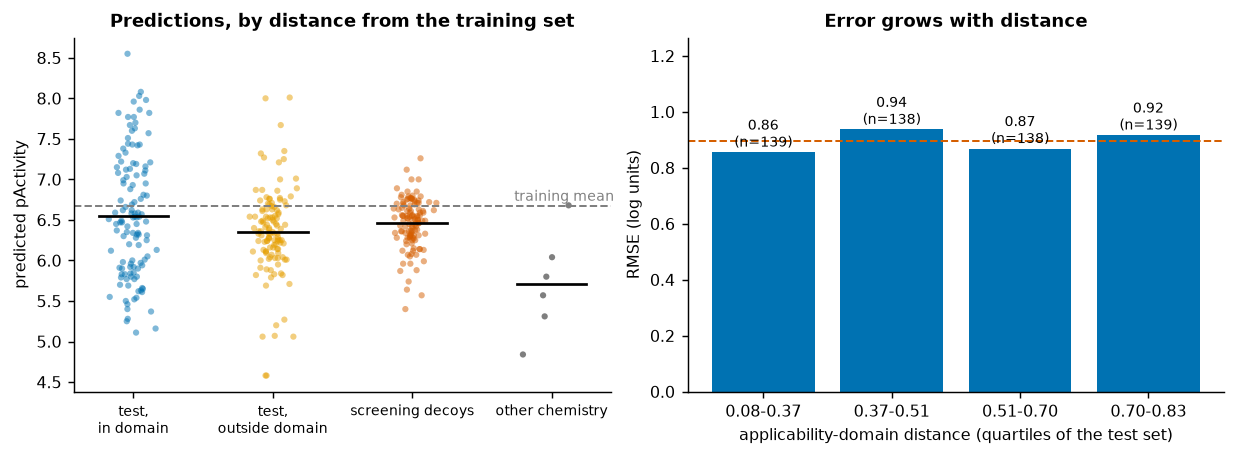

In [12]:
# The same result as a figure: predictions collapse towards the training mean as distance grows.
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.4), layout="constrained")
ax = axes[0]
colours = ["#0072B2", "#E69F00", "#D55E00", "#000000"]
for i, (name, results) in enumerate(groups.items()):
    preds = [r["pActivity"] for r in results if r["status"] == "ok"]
    ax.scatter(np.full(len(preds), i) + rng.normal(0, 0.07, len(preds)), preds,
               s=12, alpha=0.5, color=colours[i], edgecolors="none")
    ax.plot([i - 0.25, i + 0.25], [np.mean(preds)] * 2, color="black", lw=1.5)
ax.axhline(y[TR].mean(), color="grey", ls="--", lw=1.1)
ax.text(3.45, y[TR].mean() + 0.06, "training mean", ha="right", fontsize=8, color="grey")
ax.set_xticks(range(4), [g.replace(", ", ",\n") for g in groups], fontsize=7.5)
ax.set_ylabel("predicted pActivity"); ax.set_title("Predictions, by distance from the training set")

ax = axes[1]
bins = np.quantile(d_test, [0, 0.25, 0.5, 0.75, 1.0])
labels, rmses, counts = [], [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    sel = (d_test >= lo) & (d_test <= hi)
    labels.append(f"{lo:.2f}-{hi:.2f}")
    rmses.append(float(np.sqrt(np.mean((pred_te[sel] - y[TE][sel]) ** 2))))
    counts.append(int(sel.sum()))
bars = ax.bar(labels, rmses, color="#0072B2")
for b, v, c in zip(bars, rmses, counts):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.2f}\n(n={c})", ha="center", fontsize=7.5)
ax.axhline(rmse_te, color="#D55E00", ls="--", lw=1.1)
ax.set_xlabel("applicability-domain distance (quartiles of the test set)")
ax.set_ylabel("RMSE (log units)"); ax.set_ylim(0, max(rmses) * 1.35)
ax.set_title("Error grows with distance")
plt.show()
print("RMSE by AD-distance quartile:", [round(v, 3) for v in rmses],
      f"| overall {rmse_te:.3f}")
print(f"predictions for the exotic molecules span "
      f"{min(r['pActivity'] for r in groups['other chemistry']):.2f} to "
      f"{max(r['pActivity'] for r in groups['other chemistry']):.2f}, "
      f"around a training mean of {y[TR].mean():.2f}")

<p class="caption"><b>Figure 3.</b> Silent extrapolation, measured. Left: predictions for four groups of molecules at increasing distance from the training set, with the group means as black bars and the training mean as a dashed line. As the chemistry becomes unfamiliar the spread of the predictions collapses — the decoys receive potencies with less than half the spread of the in-domain test compounds, clustered around the training mean — while the group means stay comfortably inside the range a chemist would read as "weakly to moderately active". Table sugar is assigned a potency equal to the training mean, an IC50 of a few hundred nanomolar, and nothing in that number says it is meaningless. Right: the root-mean-square error of the test set by quartile of applicability-domain distance. It is essentially flat — around 0.9 log units in every quartile — and that negative result matters as much as the left-hand panel: <em>within</em> a scaffold-split test set every compound already comes from an unseen chemotype, so the distance has little left to grade. The flag earns its place by excluding the chemistry shown on the left, not by ranking the compounds the model was always going to be asked about.</p>

None of this means the model is bad: its error on the scaffold test set is within a small factor of the roughly half a log unit of experimental noise in the source data<sup class="c"><a href="#r23">[23]</a></sup>. The lesson is that **the output of a model carries no information about whether it should have been produced**, so the interface must carry it instead. Three mechanisms do that, and all three are in the prediction contract: the validation of Section 4 refuses what is obviously outside the chemistry, the applicability-domain distance flags what is subtly outside it, and the conformal interval widens the claim to a range whose coverage has been measured. An interface that shows the number and hides the other three is the thing this unit exists to prevent.

<div class="exercise"><h4>Exercise 1</h4>
<p>The applicability-domain threshold used here is the 95th percentile of the training compounds' own distances. Recompute the degradation table for thresholds at the 75th and 99th percentiles, and decide which you would ship. State the decision as a trade-off: how many useful predictions does the strict threshold refuse, and how much error does the permissive one admit?</p></div>

## 7. The application: Streamlit, line by line

Streamlit turns a Python script into a web application by re-running the script top to bottom on every interaction and rendering whatever the script writes<sup class="c"><a href="#r6">[6]</a></sup>. That execution model explains both its appeal — no callbacks, no HTML, no JavaScript — and its one rule: anything expensive must be cached, or it is recomputed on every keystroke.

The complete application is written below and explained afterwards. It cannot be served from a notebook that must terminate, so the code is printed; the function it calls, `predict_compound`, is the one already exercised above.

In [13]:
# app.py - the complete Streamlit application.
DQ = chr(34) * 3
APP = textwrap.dedent('''
    <<DQ>>Streamlit application for the ROCK1 potency predictor.

    Run with:  streamlit run app.py
    <<DQ>>
    from pathlib import Path

    import joblib
    import pandas as pd
    import streamlit as st
    from rdkit import Chem
    from rdkit.Chem import Draw

    from rockserve.predict import predict_compound, load_bundle   # the package of Unit 24

    MODEL_PATH = Path(__file__).parent / "artefacts" / "rock1_rf_v1.0.0.joblib"

    st.set_page_config(page_title="ROCK1 potency predictor", page_icon=None, layout="centered")

    @st.cache_resource                      # loaded once per server process, not per interaction
    def get_bundle():
        <<DQ>>Load the model bundle and verify the environment it was built in.<<DQ>>
        return load_bundle(MODEL_PATH, strict=False)

    bundle = get_bundle()

    st.title("ROCK1 potency predictor")
    st.caption(
        f"Random forest on Morgan fingerprints and physicochemical descriptors, "
        f"model version {bundle['version']}. Scaffold-split test RMSE "
        f"{bundle['metrics']['RMSE']:.2f} log units on {bundle['metrics']['n_test']} compounds. "
        "Predictions are estimates, not measurements."
    )

    with st.sidebar:                        # controls that change the contract, not the chemistry
        confidence = st.select_slider("Confidence level", options=[0.80, 0.90, 0.95], value=0.90)
        show_explanation = st.checkbox("Show feature attributions", value=True)
        st.divider()
        st.markdown(
            "**Privacy.** Structures are processed in memory and never stored. "
            "For confidential compounds, run this app locally: "
            "`pip install rockserve && streamlit run app.py`."
        )

    smiles = st.text_input("SMILES string", value="CC(C)c1ccccc1NC(=O)c1ccc(-c2cn[nH]c2)cc1")
    uploaded = st.file_uploader("...or upload a CSV with a 'smiles' column", type="csv")

    def render_one(result):
        <<DQ>>Render one prediction: the number, its interval, the domain verdict, the evidence.<<DQ>>
        if result["status"] == "rejected":
            st.error(f"Input rejected: {result['reason']}")
            return
        if result["note"]:
            st.warning(f"Input modified before prediction - {result['note']}")

        low, high = result["interval"]
        col_a, col_b, col_c = st.columns(3)
        col_a.metric("pActivity", f"{result['pActivity']:.2f}",
                     help="-log10 of the predicted IC50/Ki in molar units")
        col_b.metric(f"{int(100*result['confidence'])}% interval", f"{low:.2f} - {high:.2f}",
                     help="Inductive conformal interval calibrated on held-out compounds")
        col_c.metric("IC50 estimate", f"{result['IC50_nM_estimate']:,.0f} nM")

        domain = result["applicability"]
        if domain["in_domain"]:
            st.success(f"Inside the applicability domain "
                       f"(distance {domain['distance']:.2f} <= {domain['threshold']:.2f}).")
        else:
            st.error(
                f"OUTSIDE the applicability domain (distance {domain['distance']:.2f} > "
                f"{domain['threshold']:.2f}). This molecule is unlike the training compounds; "
                "the number above is an extrapolation and should not be used to rank candidates."
            )

        mol = Chem.MolFromSmiles(result["standard_smiles"])
        st.image(Draw.MolToImage(mol, size=(320, 240)), caption=result["standard_smiles"])

        st.subheader("Most similar training compounds")
        st.dataframe(pd.DataFrame(result["nearest_training_compounds"]), hide_index=True)

        if show_explanation and "top_features" in result:
            st.subheader("Largest contributions to this prediction")
            st.bar_chart(pd.DataFrame(result["top_features"]).set_index("feature"))

    if uploaded is not None:                # batch mode: a table in, a table out
        frame = pd.read_csv(uploaded)
        if "smiles" not in frame.columns:
            st.error("The uploaded file needs a column named 'smiles'.")
        else:
            rows = [predict_compound(s, bundle=bundle, confidence=confidence, explain=False)
                    for s in frame["smiles"].head(500)]
            table = pd.json_normalize(rows)
            st.dataframe(table, hide_index=True)
            st.download_button("Download predictions", table.to_csv(index=False),
                               file_name="rock1_predictions.csv", mime="text/csv")
    elif smiles:
        with st.spinner("Predicting..."):
            render_one(predict_compound(smiles, bundle=bundle, confidence=confidence,
                                        explain=show_explanation))

    st.divider()
    st.caption(
        "Model card: https://github.com/<organisation>/rockserve/blob/main/MODEL_CARD.md | "
        "Code: MIT | Model and training data: CC BY-SA 3.0 (ChEMBL) | "
        "Contact: lbqc@ucm.cl"
    )
''').lstrip().replace("<<DQ>>", DQ)
(WORK / "app.py").write_text(APP)
print(APP)
print(f"[{len(APP.splitlines())} lines]")

"""Streamlit application for the ROCK1 potency predictor.

Run with:  streamlit run app.py
"""
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st
from rdkit import Chem
from rdkit.Chem import Draw

from rockserve.predict import predict_compound, load_bundle   # the package of Unit 24

MODEL_PATH = Path(__file__).parent / "artefacts" / "rock1_rf_v1.0.0.joblib"

st.set_page_config(page_title="ROCK1 potency predictor", page_icon=None, layout="centered")

@st.cache_resource                      # loaded once per server process, not per interaction
def get_bundle():
    """Load the model bundle and verify the environment it was built in."""
    return load_bundle(MODEL_PATH, strict=False)

bundle = get_bundle()

st.title("ROCK1 potency predictor")
st.caption(
    f"Random forest on Morgan fingerprints and physicochemical descriptors, "
    f"model version {bundle['version']}. Scaffold-split test RMSE "
    f"{bundle['metrics']['RMSE']:.2f} log units on {bundl

Seven things in that file are deliberate.

**`@st.cache_resource` on the loader.** Streamlit re-executes the whole script on every widget change. Without the cache, a 20 MB model would be unpickled each time a user moves the slider. `cache_resource` is for objects shared across sessions (a model, a database connection); `cache_data` is for the results of computations on serialisable inputs.

**The caption states the model's identity and error.** Version and scaffold-split RMSE appear above the input box, not in a document nobody opens. A user who sees "RMSE 0.9 log units" reads the prediction differently.

**The applicability-domain verdict is an error box, not a footnote.** Out-of-domain is displayed in red with a sentence saying what it means and what not to do with the number. This single widget is the difference between a tool that misleads and one that does not.

**The input is echoed after standardisation.** The depicted molecule is what the model actually saw. A user who pasted a salt sees the parent.

**The evidence is shown, not just the answer.** The three nearest training compounds with their measured potencies let a chemist judge the prediction with their own expertise, which is more persuasive than any feature attribution.

**Batch mode is capped and explicit.** Five hundred rows, no explanations, a download button. The cap exists because a free-tier container has one core and a request timeout.

**The privacy statement is in the sidebar, where a user looking for it will look.** It says what happens to uploaded structures and offers the local alternative.

the red band is the only element whose absence would make this tool dangerous


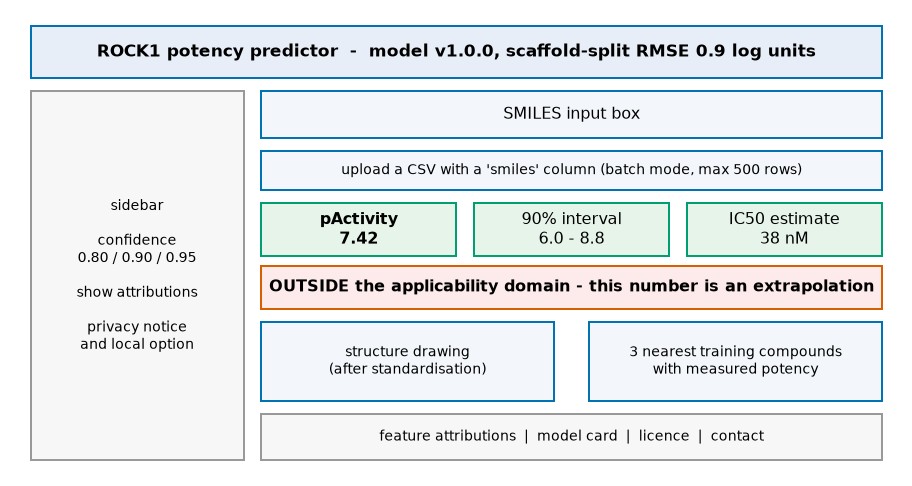

In [14]:
# A wireframe of the application, drawn here so the layout can be discussed without a server.
fig, ax = plt.subplots(figsize=(8.8, 4.6))
ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 7)
def box(x, y, w, h, label, fc="#f3f6fa", ec="#0072B2", fs=8.5, weight="normal"):
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=fc, edgecolor=ec, lw=1.1))
    ax.text(x + w / 2, y + h / 2, label, ha="center", va="center", fontsize=fs, fontweight=weight)
box(0.2, 6.0, 9.6, 0.8, "ROCK1 potency predictor  -  model v1.0.0, scaffold-split RMSE 0.9 log units",
    fc="#e8eef7", fs=9.5, weight="bold")
box(0.2, 0.2, 2.4, 5.6, "sidebar\n\nconfidence\n0.80 / 0.90 / 0.95\n\nshow attributions\n\nprivacy notice\nand local option",
    fc="#f7f7f7", ec="#999999", fs=8)
box(2.8, 5.1, 7.0, 0.7, "SMILES input box", fs=9)
box(2.8, 4.3, 7.0, 0.6, "upload a CSV with a 'smiles' column (batch mode, max 500 rows)", fs=8)
box(2.8, 3.3, 2.2, 0.8, "pActivity\n7.42", fc="#e6f4ea", ec="#009E73", fs=9, weight="bold")
box(5.2, 3.3, 2.2, 0.8, "90% interval\n6.0 - 8.8", fc="#e6f4ea", ec="#009E73", fs=9)
box(7.6, 3.3, 2.2, 0.8, "IC50 estimate\n38 nM", fc="#e6f4ea", ec="#009E73", fs=9)
box(2.8, 2.5, 7.0, 0.65, "OUTSIDE the applicability domain - this number is an extrapolation",
    fc="#fdeaea", ec="#D55E00", fs=9, weight="bold")
box(2.8, 1.1, 3.3, 1.2, "structure drawing\n(after standardisation)", fs=8)
box(6.5, 1.1, 3.3, 1.2, "3 nearest training compounds\nwith measured potency", fs=8)
box(2.8, 0.2, 7.0, 0.7, "feature attributions  |  model card  |  licence  |  contact", fs=8,
    fc="#f7f7f7", ec="#999999")
plt.show()
print("the red band is the only element whose absence would make this tool dangerous")

<p class="caption"><b>Figure 4.</b> Layout of the application. The prediction, its interval and the derived IC50 occupy one row; immediately beneath them, and at full width, sits the applicability-domain verdict. Below that is the evidence a chemist can judge directly — the standardised structure and the nearest training compounds with their <em>measured</em> potencies. Gradio produces a similar interface from a function signature and a list of input and output components<sup class="c"><a href="#r3">[3]</a></sup>; the design decisions above are identical in either framework.</p>

## 8. The API: FastAPI, schemas and testing

An application serves people; an API serves programs. FastAPI builds one from type annotations: a Pydantic model describes the request and the response, FastAPI validates incoming JSON against it, returns a structured 422 error when it does not match, and publishes an OpenAPI specification from which clients can be generated.

In [15]:
# api.py - the complete FastAPI service.
API = textwrap.dedent('''
    <<DQ>>REST API for the ROCK1 potency predictor.

    Run with:  uvicorn api:app --host 0.0.0.0 --port 8000
    Interactive documentation is then served at /docs, the OpenAPI schema at /openapi.json.
    <<DQ>>
    import logging
    import os
    import time
    from pathlib import Path
    from typing import Literal

    from fastapi import Depends, FastAPI, Header, HTTPException
    from pydantic import BaseModel, Field

    from rockserve.predict import load_bundle, predict_compound

    MODEL_PATH = Path(os.environ.get("ROCK1_MODEL", "artefacts/rock1_rf_v1.0.0.joblib"))
    API_KEY = os.environ.get("ROCK1_API_KEY")          # secret from the environment, never in code
    MAX_BATCH = 200

    logging.basicConfig(level=logging.INFO,
                        format="%(asctime)s %(levelname)s %(name)s %(message)s")
    logger = logging.getLogger("rockserve")

    app = FastAPI(title="ROCK1 potency predictor", version="1.0.0",
                  description="Predicted pActivity with a conformal interval and an "
                              "applicability-domain verdict. Not for clinical use.")
    BUNDLE = load_bundle(MODEL_PATH, strict=True)      # fail at start-up, not on the first request


    class PredictRequest(BaseModel):
        <<DQ>>One or more structures and the confidence level for the interval.<<DQ>>

        smiles: list[str] = Field(..., min_length=1, max_length=MAX_BATCH,
                                  examples=[["CC(=O)Oc1ccccc1C(=O)O"]])
        confidence: Literal[0.80, 0.90, 0.95] = 0.90
        explain: bool = False


    class Applicability(BaseModel):
        distance: float
        threshold: float
        in_domain: bool


    class Prediction(BaseModel):
        <<DQ>>The prediction contract, one entry per input structure.<<DQ>>

        status: Literal["ok", "rejected"]
        input: str
        standard_smiles: str | None = None
        pActivity: float | None = None
        interval: list[float] | None = None
        IC50_nM_estimate: float | None = None
        applicability: Applicability | None = None
        reason: str | None = None


    class PredictResponse(BaseModel):
        model_version: str
        n_requested: int
        n_rejected: int
        elapsed_ms: float
        predictions: list[Prediction]


    def require_key(x_api_key: str | None = Header(default=None)):
        <<DQ>>Reject the request when an API key is configured and not supplied.<<DQ>>
        if API_KEY and x_api_key != API_KEY:
            raise HTTPException(status_code=401, detail="invalid or missing X-API-Key header")


    @app.get("/health")
    def health():
        <<DQ>>Liveness probe used by the hosting platform and by monitoring.<<DQ>>
        return {"status": "ok", "model_version": BUNDLE["version"]}


    @app.get("/model")
    def model_info():
        <<DQ>>The manifest: what this service is serving, and how well it does.<<DQ>>
        return {"version": BUNDLE["version"], "metrics": BUNDLE["metrics"],
                "training_data": BUNDLE["training_data"],
                "applicability_domain": {"measure": "1 - mean Tanimoto to 5 nearest training "
                                                    "compounds", "threshold": BUNDLE["ad_threshold"]},
                "model_card": "https://github.com/<organisation>/rockserve/blob/main/MODEL_CARD.md"}


    @app.post("/predict", response_model=PredictResponse, dependencies=[Depends(require_key)])
    def predict(request: PredictRequest):
        <<DQ>>Predict potency for up to 200 structures.<<DQ>>
        started = time.perf_counter()
        results = [predict_compound(s, bundle=BUNDLE, confidence=request.confidence,
                                    explain=request.explain) for s in request.smiles]
        elapsed = 1000 * (time.perf_counter() - started)
        n_rejected = sum(r["status"] == "rejected" for r in results)
        logger.info("predict n=%d rejected=%d elapsed_ms=%.0f version=%s",
                    len(results), n_rejected, elapsed, BUNDLE["version"])   # no structures logged
        return PredictResponse(model_version=BUNDLE["version"], n_requested=len(results),
                               n_rejected=n_rejected, elapsed_ms=round(elapsed, 1),
                               predictions=results)
''').lstrip().replace("<<DQ>>", DQ)
(WORK / "api.py").write_text(API)
print(API)
print(f"[{len(API.splitlines())} lines]")

"""REST API for the ROCK1 potency predictor.

Run with:  uvicorn api:app --host 0.0.0.0 --port 8000
Interactive documentation is then served at /docs, the OpenAPI schema at /openapi.json.
"""
import logging
import os
import time
from pathlib import Path
from typing import Literal

from fastapi import Depends, FastAPI, Header, HTTPException
from pydantic import BaseModel, Field

from rockserve.predict import load_bundle, predict_compound

MODEL_PATH = Path(os.environ.get("ROCK1_MODEL", "artefacts/rock1_rf_v1.0.0.joblib"))
API_KEY = os.environ.get("ROCK1_API_KEY")          # secret from the environment, never in code
MAX_BATCH = 200

logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s %(levelname)s %(name)s %(message)s")
logger = logging.getLogger("rockserve")

app = FastAPI(title="ROCK1 potency predictor", version="1.0.0",
              description="Predicted pActivity with a conformal interval and an "
                          "applicability-domain verdict.

The design decisions, in the order a reviewer would question them.

**The model is loaded at import, with `strict=True`.** A service that starts successfully and fails on the first request is harder to diagnose than one that refuses to start. The environment check of Section 3 runs here.

**The request schema bounds the input.** `min_length=1, max_length=200` and a `Literal` for the confidence level mean that a malformed or oversized request is rejected by FastAPI with a 422 and a precise message, before any chemistry runs. The batch cap is the API's defence against being used as a screening engine.

**The response schema is explicit, including the rejected case.** Every field a client may read is declared, and a structure that fails validation returns `status: "rejected"` with a reason *inside* a 200 response rather than failing the whole batch.

**`/health` and `/model` exist.** The first is what the platform polls to decide whether the container is alive; the second is what a user — or a referee — calls to learn which version produced a number, with a link to the model card.

**The secret comes from the environment.** `os.environ.get("ROCK1_API_KEY")` and a header dependency: no key in the source, in the repository or in the image. If no key is configured the service is open, which is a deliberate default for an internal tool and a deliberate decision to document.

**The log line records counts, not chemistry.** Structures are confidential; `n=12 rejected=1 elapsed_ms=380 version=1.0.0` is enough to monitor usage and latency without storing anyone's compounds.

A test suite for this service uses FastAPI's `TestClient`, which exercises the application in-process without a network: `client.post("/predict", json={"smiles": ["CCO"]})` returns a response object whose `status_code` and `json()` are asserted exactly as in Unit 24. The checks worth writing are the schema rejection (a 422 for a bad payload), the authentication path (401 without the header), the rejected-structure path, and a golden test that a reference molecule still receives the same prediction to three decimals.

The cell below simulates the endpoint locally: it builds the request payload, calls the same function the endpoint calls, and prints the JSON a client would receive.

In [16]:
# A simulated request/response cycle: the payload a client sends and the JSON it receives.
request_payload = {"smiles": ["CC(C)c1ccccc1NC(=O)c1ccc(-c2cn[nH]c2)cc1",   # kinase-like
                              "Cn1c(=O)c2c(ncn2C)n(C)c1=O",                 # caffeine
                              "fasudil"],                                    # not a SMILES
                   "confidence": 0.90, "explain": False}
started = time.perf_counter()
results = [predict_compound(s, confidence=request_payload["confidence"], explain=False)
           for s in request_payload["smiles"]]
elapsed_ms = 1000 * (time.perf_counter() - started)
response = {"model_version": MODEL_VERSION, "n_requested": len(results),
            "n_rejected": sum(r["status"] == "rejected" for r in results),
            "elapsed_ms": round(elapsed_ms, 1),
            "predictions": [{k: v for k, v in r.items()
                             if k in ("status", "input", "standard_smiles", "pActivity",
                                      "interval", "IC50_nM_estimate", "applicability", "reason")}
                            for r in results]}
print("POST /predict  (X-API-Key: ...)\n")
print(json.dumps(request_payload, indent=1))
print("\n200 OK\n")
print(json.dumps(response, indent=1))
print(f"\nserver-side log line: predict n={response['n_requested']} "
      f"rejected={response['n_rejected']} elapsed_ms={response['elapsed_ms']:.0f} "
      f"version={MODEL_VERSION}")

POST /predict  (X-API-Key: ...)

{
 "smiles": [
  "CC(C)c1ccccc1NC(=O)c1ccc(-c2cn[nH]c2)cc1",
  "Cn1c(=O)c2c(ncn2C)n(C)c1=O",
  "fasudil"
 ],
 "confidence": 0.9,
 "explain": false
}

200 OK

{
 "model_version": "1.0.0",
 "n_requested": 3,
 "n_rejected": 1,
 "elapsed_ms": 55.7,
 "predictions": [
  {
   "status": "ok",
   "input": "CC(C)c1ccccc1NC(=O)c1ccc(-c2cn[nH]c2)cc1",
   "standard_smiles": "CC(C)c1ccccc1NC(=O)c1ccc(-c2cn[nH]c2)cc1",
   "pActivity": 7.09,
   "interval": [
    5.69,
    8.49
   ],
   "IC50_nM_estimate": 81.5,
   "applicability": {
    "distance": 0.518,
    "threshold": 0.49,
    "in_domain": false
   }
  },
  {
   "status": "ok",
   "input": "Cn1c(=O)c2c(ncn2C)n(C)c1=O",
   "standard_smiles": "Cn1c(=O)c2c(ncn2C)n(C)c1=O",
   "pActivity": 5.31,
   "interval": [
    3.91,
    6.71
   ],
   "IC50_nM_estimate": 4870.8,
   "applicability": {
    "distance": 0.842,
    "threshold": 0.49,
    "in_domain": false
   }
  },
  {
   "status": "rejected",
   "reason": "not a par

the four exits correspond to the four tests the service needs: bad payload, missing key,
unparsable structure, and a reference molecule whose prediction must not change


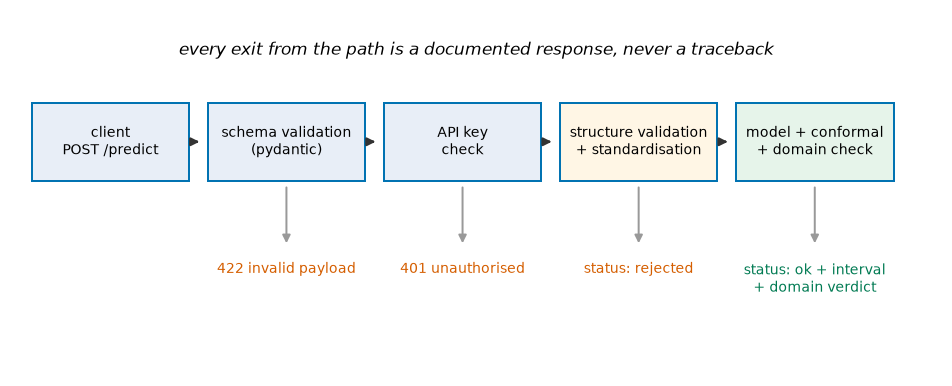

In [17]:
# The request path, drawn: what happens between the client and the model.
fig, ax = plt.subplots(figsize=(9.2, 3.6))
ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 6)
stages = [("client\nPOST /predict", 0.2, "#e8eef7"), ("schema validation\n(pydantic)", 2.1, "#e8eef7"),
          ("API key\ncheck", 4.0, "#e8eef7"), ("structure validation\n+ standardisation", 5.9, "#fff6e5"),
          ("model + conformal\n+ domain check", 7.8, "#e6f4ea")]
for label, x, colour in stages:
    ax.add_patch(plt.Rectangle((x, 3.2), 1.7, 1.3, facecolor=colour, edgecolor="#0072B2", lw=1.1))
    ax.text(x + 0.85, 3.85, label, ha="center", va="center", fontsize=8)
    if x < 7.8:
        ax.annotate("", xy=(x + 1.85, 3.85), xytext=(x + 1.72, 3.85),
                    arrowprops=dict(arrowstyle="-|>", lw=1.3, color="#333333"))
outcomes = [("422 invalid payload", 2.95), ("401 unauthorised", 4.85),
            ("status: rejected", 6.75), ("status: ok + interval\n+ domain verdict", 8.65)]
for label, x in outcomes:
    ax.annotate("", xy=(x, 2.1), xytext=(x, 3.15),
                arrowprops=dict(arrowstyle="-|>", lw=1.1, color="#999999"))
    ax.text(x, 1.85, label, ha="center", va="top", fontsize=8,
            color="#D55E00" if "ok" not in label else "#007a52")
ax.text(5.0, 5.3, "every exit from the path is a documented response, never a traceback",
        ha="center", fontsize=9.5, style="italic")
plt.show()
print("the four exits correspond to the four tests the service needs: bad payload, missing key,")
print("unparsable structure, and a reference molecule whose prediction must not change")

<p class="caption"><b>Figure 5.</b> The path of a request through the service and its four possible exits. Validation happens in two layers — the JSON schema first, the chemistry second — so a malformed request never reaches RDKit and an unparsable structure never reaches the model. Each exit is a documented response code or status field, which is what makes the service testable.</p>

## 9. The model card and the dataset card

A **model card** is a short structured document describing what a model is for, what it was trained on, how it performs, and where it must not be used<sup class="c"><a href="#r1">[1]</a></sup>. It was proposed to prevent exactly the failure measured in Section 6: a model used outside the conditions in which it was evaluated. The equivalent for the data is a **datasheet** or dataset card<sup class="c"><a href="#r2">[2]</a></sup>, and in chemistry both overlap with the OECD/QMRF reporting of Unit 23 and with the DOME recommendations for machine learning in the life sciences<sup class="c"><a href="#r8">[8]</a><a href="#r9">[9]</a><a href="#r10">[10]</a></sup>.

The figures below are the evidence the card cites; the card itself is generated from the same variables in the cell after them.

in-domain test RMSE 0.899 vs outside 0.892
interval widths at 80/90/95%: [2.24, 2.8, 3.33] log units; empirical coverage [np.float64(0.791), np.float64(0.875), np.float64(0.926)]
median distance: training 0.27, test 0.51, decoys 0.77; threshold 0.49


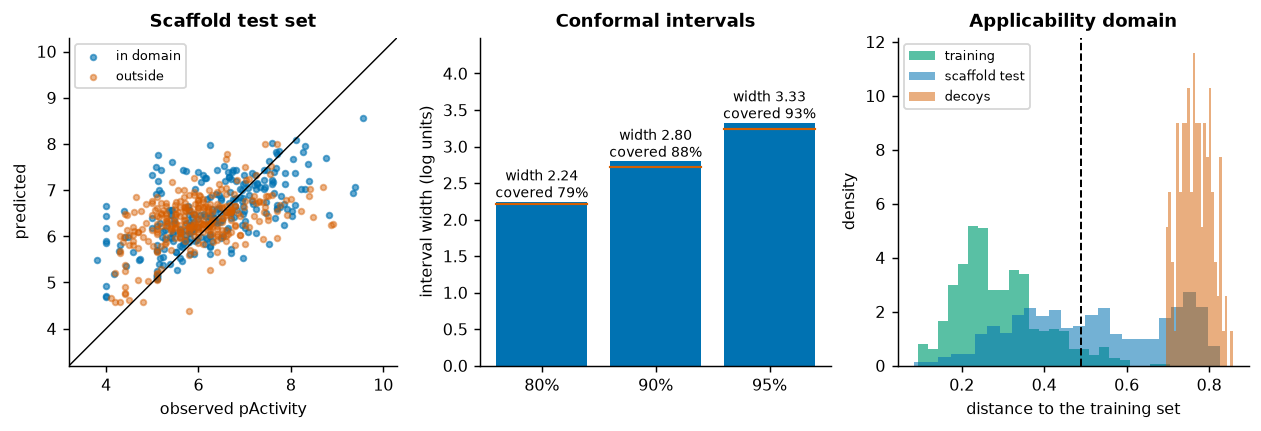

In [18]:
# The three figures a model card must be able to point at.
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.2), layout="constrained")
ax = axes[0]
ax.scatter(y[TE][inside], pred_te[inside], s=10, alpha=0.6, color="#0072B2", label="in domain")
ax.scatter(y[TE][~inside], pred_te[~inside], s=10, alpha=0.45, color="#D55E00", label="outside")
lims = (3.2, 10.3)
ax.plot(lims, lims, color="black", lw=0.8)
ax.set_xlim(*lims); ax.set_ylim(*lims); ax.set_aspect("equal")
ax.set_xlabel("observed pActivity"); ax.set_ylabel("predicted"); ax.legend(fontsize=7)
ax.set_title("Scaffold test set")

ax = axes[1]
widths = [2 * conformal_q(resid_ca, c)[0] for c in (0.80, 0.90, 0.95)]
emp = [coverage.loc[i, "empirical_all"] for i in range(3)]
bars = ax.bar(["80%", "90%", "95%"], widths, color="#0072B2")
for b, w, e, nominal in zip(bars, widths, emp, (0.80, 0.90, 0.95)):
    ax.text(b.get_x() + b.get_width()/2, w + 0.06, f"width {w:.2f}\ncovered {e:.0%}",
            ha="center", fontsize=7.5)
    ax.plot([b.get_x(), b.get_x() + b.get_width()], [w * e / nominal] * 2, color="#D55E00", lw=1.2)
ax.set_ylabel("interval width (log units)"); ax.set_ylim(0, max(widths) * 1.35)
ax.set_title("Conformal intervals")

ax = axes[2]
decoy_d = [r["applicability"]["distance"] for r in groups["screening decoys"]]
ax.hist(d_train, bins=25, alpha=0.65, color="#009E73", label="training", density=True)
ax.hist(d_test, bins=25, alpha=0.55, color="#0072B2", label="scaffold test", density=True)
ax.hist(decoy_d, bins=25, alpha=0.5, color="#D55E00", label="decoys", density=True)
ax.axvline(AD_THRESHOLD, color="black", ls="--", lw=1.1)
ax.set_xlabel("distance to the training set"); ax.set_ylabel("density"); ax.legend(fontsize=7)
ax.set_title("Applicability domain")
plt.show()
print(f"in-domain test RMSE {np.sqrt(np.mean((pred_te[inside]-y[TE][inside])**2)):.3f} vs "
      f"outside {np.sqrt(np.mean((pred_te[~inside]-y[TE][~inside])**2)):.3f}")
print(f"interval widths at 80/90/95%: {[round(w,2) for w in widths]} log units; "
      f"empirical coverage {emp}")
print(f"median distance: training {np.median(d_train):.2f}, test {np.median(d_test):.2f}, "
      f"decoys {np.median(decoy_d):.2f}; threshold {AD_THRESHOLD:.2f}")

<p class="caption"><b>Figure 6.</b> The three pieces of evidence behind the model card. Left: predicted against observed potency on the scaffold-split test set, coloured by the applicability-domain verdict. Middle: the width of the conformal interval at three confidence levels, with the empirical coverage printed above each bar and marked by the red line — note that the widths grow steeply while the coverage stays below nominal, which is what a violated exchangeability assumption looks like. Right: the distribution of distance to the training set for training compounds, for the scaffold-split test compounds and for decoys from an unrelated chemistry; the dashed line is the threshold, and the separation between the green and red distributions is why the flag is informative.</p>

{
 "pActivity": 7.09,
 "interval": [
  5.69,
  8.49
 ],
 "applicability": {
  "distance": 0.518,
  "threshold": 0.49,
  "in_domain": false
 }
}
nearest training compounds:
  Tanimoto 0.50  measured pActivity 6.69  COc1cc(C(=O)NCc2ccccc2C(C)C)ccc1-c1cn[nH]c1
  Tanimoto 0.49  measured pActivity 7.14  COc1cc(C(=O)N[C@@H](C)c2ccccc2OC)ccc1-c1cn[nH]c1
  Tanimoto 0.48  measured pActivity 7.92  CNC(C(=O)Nc1ccc(-c2cn[nH]c2)cc1)c1ccccc1OC

the attributions name fingerprint bits, which a chemist cannot read directly; the nearest
neighbours with their measured values are the explanation a medicinal chemist actually uses


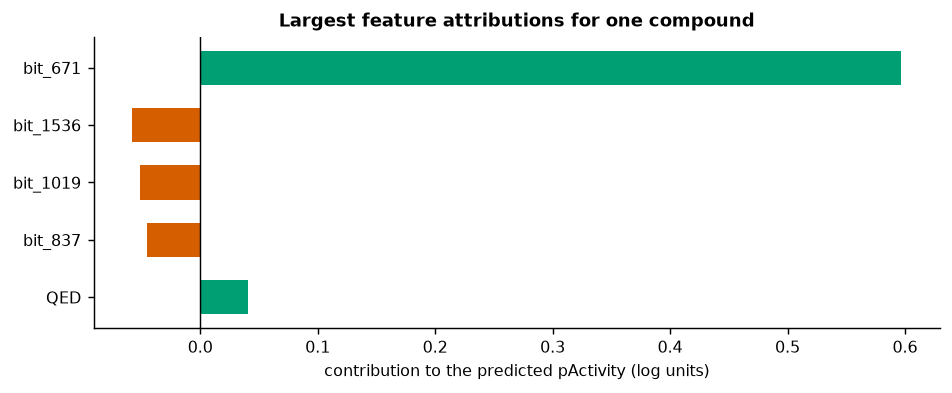

In [19]:
# One molecule's explanation, as the application would show it.
example = "CC(C)c1ccccc1NC(=O)c1ccc(-c2cn[nH]c2)cc1"
full = predict_compound(example, explain=True)
feat = pd.DataFrame(full["top_features"])
fig, ax = plt.subplots(figsize=(8.4, 2.9))
colours = ["#009E73" if v > 0 else "#D55E00" for v in feat["contribution"]]
ax.barh(feat["feature"][::-1], feat["contribution"][::-1], color=colours[::-1], height=0.6)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("contribution to the predicted pActivity (log units)")
ax.set_title("Largest feature attributions for one compound")
plt.show()
print(json.dumps({k: full[k] for k in ("pActivity", "interval", "applicability")}, indent=1))
print("nearest training compounds:")
for nb in full["nearest_training_compounds"]:
    print(f"  Tanimoto {nb['tanimoto']:.2f}  measured pActivity {nb['measured_pActivity']:.2f}  "
          f"{nb['smiles'][:52]}")
print("\nthe attributions name fingerprint bits, which a chemist cannot read directly; the nearest")
print("neighbours with their measured values are the explanation a medicinal chemist actually uses")

<p class="caption"><b>Figure 7.</b> SHAP attributions for a single prediction<sup class="c"><a href="#r11">[11]</a><a href="#r12">[12]</a></sup>: the five features that moved this compound's predicted potency furthest from the model's base value. Most are fingerprint bits, which identify substructural environments but are not self-explanatory; this is the standard limitation of explaining a fingerprint model<sup class="c"><a href="#r13">[13]</a></sup>, and the reason the interface shows the nearest measured compounds beside the attributions.</p>

In [20]:
# MODEL_CARD.md, generated from the quantities computed in this notebook.
inside_rmse = float(np.sqrt(np.mean((pred_te[inside] - y[TE][inside]) ** 2)))
outside_rmse = float(np.sqrt(np.mean((pred_te[~inside] - y[TE][~inside]) ** 2)))
CARD = f'''
# Model card - ROCK1 potency predictor (rock1-potency-rf), version {MODEL_VERSION}

## Model details
- Random-forest regression (scikit-learn {sklearn.__version__}, 300 trees, random_state={SEED},
  all other hyperparameters at library defaults) on Morgan fingerprints (radius 2, 2,048 bits,
  RDKit {rdkit.__version__}) concatenated with {len(DESC)} physicochemical descriptors
  ({X.shape[1]} features in total).
- Output: pActivity = -log10(IC50 or Ki in molar units) for human ROCK1 (ChEMBL CHEMBL3231,
  UniProt Q13464), with an inductive conformal interval and an applicability-domain verdict.
- Developed by the Laboratorio de Bioinformatica y Quimica Computacional (LBQC), Universidad
  Catolica del Maule, as teaching and internal prioritisation software. Code MIT; model and data
  CC BY-SA 3.0, inherited from ChEMBL.

## Intended use
- Intended: ranking candidate compounds for ROCK1 inhibition within the applicability domain;
  triage of purchasable libraries before docking or assay; teaching.
- Not intended: absolute potency prediction for decision-making without experimental confirmation;
  selectivity prediction against other kinases (never trained for it); any clinical, diagnostic or
  safety-related use; prediction for molecules outside the domain defined below.
- Users: medicinal chemists and computational colleagues; outputs are estimates, not measurements.

## Training data
- Source: ChEMBL release 37 (2026-05-01), target CHEMBL3231, IC50/Ki/Kd, human.
- Curation: standardised parent structures keyed by InChIKey; median of exact measurements per
  compound; censored records excluded from the regression target ({int(df['censored'].sum())}
  compounds). {len(exact)} compounds with exact values remain.
- Split: deterministic Bemis-Murcko scaffold split - train {len(TR)}, calibration {len(CA)},
  test {len(TE)}; no scaffold is shared between the parts.
- Known biases: the data are an aggregate of many laboratories and assay formats; actives are
  over-represented relative to any realistic library; the chemistry is concentrated in a few
  scaffold families, so the model knows amide-linked kinase hinge binders far better than anything
  else.

## Metrics (scaffold hold-out, n = {len(TE)})
- RMSE {rmse_te:.2f}, MAE {mae_te:.2f}, R2 {r2_te:.2f} log units.
- Pooled experimental standard deviation of replicate measurements in the source data: about 0.5
  log units; the model's error is therefore within a small factor of the measurement itself.
- Conformal intervals: half-widths {', '.join(f'{conformal_q(resid_ca, c)[0]:.2f}' for c in (0.8, 0.9, 0.95))}
  log units at 80/90/95 % nominal confidence; empirical coverage on the scaffold test set
  {', '.join(f"{coverage.loc[i, 'empirical_all']:.0%}" for i in range(3))} - below nominal, because a
  scaffold split violates the exchangeability assumption.
- By domain: RMSE {inside_rmse:.2f} inside the applicability domain against {outside_rmse:.2f} outside.

## Applicability domain
- Definition: 1 minus the mean Tanimoto similarity (Morgan radius 2, 2,048 bits) to the five most
  similar training compounds; a molecule is inside when that distance is at most
  {AD_THRESHOLD:.2f}, the 95th percentile of the training compounds' own distances.
- {100*inside.mean():.0f} % of the scaffold-split test compounds fall inside. Predictions for
  molecules outside the domain revert towards the training mean of {y[TR].mean():.2f} and must be
  treated as refusals, not as estimates.
- Hard limits enforced before prediction: 3-70 heavy atoms, elements restricted to
  {', '.join(sorted(ALLOWED_ELEMENTS))}, largest fragment of a mixture, neutralised.

## Limitations and ethical considerations
- Public bioactivity data are heterogeneous and incomplete; absence of a measurement is not
  evidence of inactivity, and censored values were excluded rather than modelled.
- The model predicts potency only. It says nothing about selectivity, toxicity, solubility,
  synthesisability or the suitability of a compound for any use in animals or humans.
- Deployed as a web service, it processes structures that may be confidential; the service stores
  no structures and logs only counts and timings.
- Environmental and resource cost is negligible (seconds of CPU per fit), and the data carry a
  share-alike licence that obliges redistribution under the same terms.

## Maintenance
- Version {MODEL_VERSION}, built 2026-10-18 from the frozen curated table
  (sha256 {manifest['training_data']['sha256']}).
- Retraining when ChEMBL adds a substantial number of ROCK1 measurements (reviewed yearly) or when
  a dependency upgrade changes the environment check.
- Contact: lbqc@ucm.cl. Issues and the deposited code: the repository linked from the service.
'''
(WORK / "MODEL_CARD.md").write_text(CARD.strip())
print(CARD.strip())
print(f"\n[{len(CARD.split())} words]")

# Model card - ROCK1 potency predictor (rock1-potency-rf), version 1.0.0

## Model details
- Random-forest regression (scikit-learn 1.9.0, 300 trees, random_state=0,
  all other hyperparameters at library defaults) on Morgan fingerprints (radius 2, 2,048 bits,
  RDKit 2026.03.4) concatenated with 11 physicochemical descriptors
  (2059 features in total).
- Output: pActivity = -log10(IC50 or Ki in molar units) for human ROCK1 (ChEMBL CHEMBL3231,
  UniProt Q13464), with an inductive conformal interval and an applicability-domain verdict.
- Developed by the Laboratorio de Bioinformatica y Quimica Computacional (LBQC), Universidad
  Catolica del Maule, as teaching and internal prioritisation software. Code MIT; model and data
  CC BY-SA 3.0, inherited from ChEMBL.

## Intended use
- Intended: ranking candidate compounds for ROCK1 inhibition within the applicability domain;
  triage of purchasable libraries before docking or assay; teaching.
- Not intended: absolute potency prediction for d

In [21]:
# DATA_CARD.md - shorter, and about the data rather than the model.
DATA_CARD = f'''
# Dataset card - ROCK1 curated bioactivity table

- **What it is.** {len(df)} compounds with measured affinity for human ROCK1, one row per
  standardised parent structure, derived from {int(df['n_measurements'].sum())} activity records.
- **Provenance.** ChEMBL 37 (CHEMBL3231), downloaded 2026-10-18; standardisation and aggregation by
  the curation package of Unit 24; sha256 {manifest['training_data']['sha256']}.
- **Composition.** {len(exact)} compounds with at least one exact measurement (the modelling set)
  and {int(df['censored'].sum())} whose measurements are all censored (">" or "<"), kept and
  flagged. Potency range {exact['pActivity'].min():.2f}-{exact['pActivity'].max():.2f},
  median {exact['pActivity'].median():.2f}.
- **Collection process.** Aggregated by ChEMBL from the medicinal-chemistry literature: many
  laboratories, assay formats (binding and functional) and years. Replicate measurements of the same
  compound differ by about 0.5 log units on average.
- **Known gaps and biases.** Publication bias towards potent compounds; scaffold concentration
  ({exact['scaffold_smiles'].nunique()} scaffolds for {len(exact)} compounds, many singletons);
  no negative data in the usual sense; no information about compound purity or aggregation.
- **Recommended uses.** Model development with scaffold- or cluster-based splits; teaching.
  **Discouraged.** Treating censored records as exact; random splits for performance claims about
  new chemotypes; comparing values across assay types without care.
- **Licence.** CC BY-SA 3.0 (ChEMBL); cite Zdrazil et al. 2024, doi:10.1093/nar/gkad1004.
'''
(WORK / "DATA_CARD.md").write_text(DATA_CARD.strip())
print(DATA_CARD.strip())

# Dataset card - ROCK1 curated bioactivity table

- **What it is.** 4280 compounds with measured affinity for human ROCK1, one row per
  standardised parent structure, derived from 5045 activity records.
- **Provenance.** ChEMBL 37 (CHEMBL3231), downloaded 2026-10-18; standardisation and aggregation by
  the curation package of Unit 24; sha256 765ab0cf633b4dd26a9be200f21c7972.
- **Composition.** 2764 compounds with at least one exact measurement (the modelling set)
  and 1516 whose measurements are all censored (">" or "<"), kept and
  flagged. Potency range 3.57-9.82,
  median 6.44.
- **Collection process.** Aggregated by ChEMBL from the medicinal-chemistry literature: many
  laboratories, assay formats (binding and functional) and years. Replicate measurements of the same
  compound differ by about 0.5 log units on average.
- **Known gaps and biases.** Publication bias towards potent compounds; scaffold concentration
  (1218 scaffolds for 2764 compounds, many singletons);
  no negati

## 10. Deploying it, keeping it alive, and switching it off

The deployment itself is the easy part. A Streamlit application goes to Streamlit Community Cloud or a Hugging Face Space by pointing the platform at a repository containing `app.py`, a pinned `requirements.txt` and the model artefact (or a download step for it); a FastAPI service goes to a Space with a Docker runtime, or to any small container host, using the image of Unit 25. What follows deployment is the part that is routinely skipped.

**Secrets.** API keys, tokens and database URLs are injected as environment variables through the platform's secrets interface and read with `os.environ`. They are never in the repository, never in the image, never in a notebook and never printed in a log — a key committed once is a key to rotate, because the history keeps it.

**Logging.** Log counts, latencies, versions and error classes; do not log user structures. If usage analysis requires some record of what was asked, store a hash, state that in the privacy notice, and set a retention period.

**Versioning, twice over.** The application and the model have independent versions, and the response carries both: `model_version` in every payload, and the app version in the footer. A user who reports "the number changed" must be able to tell which of the two moved.

**Monitoring.** A `/health` endpoint the platform polls; an alert on error rate and on latency; and — specific to scientific services — a periodic check of the *distribution of what users submit*. A rising fraction of out-of-domain submissions is the signal that the tool is being used for something it was not built for, and that is a scientific problem before it is an engineering one<sup class="c"><a href="#r4">[4]</a><a href="#r5">[5]</a></sup>.

**Archiving.** The repository, the model artefact and the manifest are deposited and given a DOI at each release, which is what makes the software citable<sup class="c"><a href="#r27">[27]</a></sup> and what the FAIR principles for research software ask of a deposited tool<sup class="c"><a href="#r26">[26]</a></sup>.

**Maintenance and sunset.** A deployed tool is a commitment with no natural end, and free tiers sleep, change their runtimes and occasionally disappear. The group's policy, written into the model card and the README of every deployed tool, has four clauses: the service is maintained for a stated period after publication; dependencies are pinned and reviewed annually; if the tool is retired, the repository, the model artefact and an archived DOI remain, with instructions to run it locally; and the publication never cites the URL alone — it cites the archived artefact, because the paper must stay reproducible after the server is gone.

the commitments in the model card are what make the last event an orderly retirement
rather than a dead link in a published paper


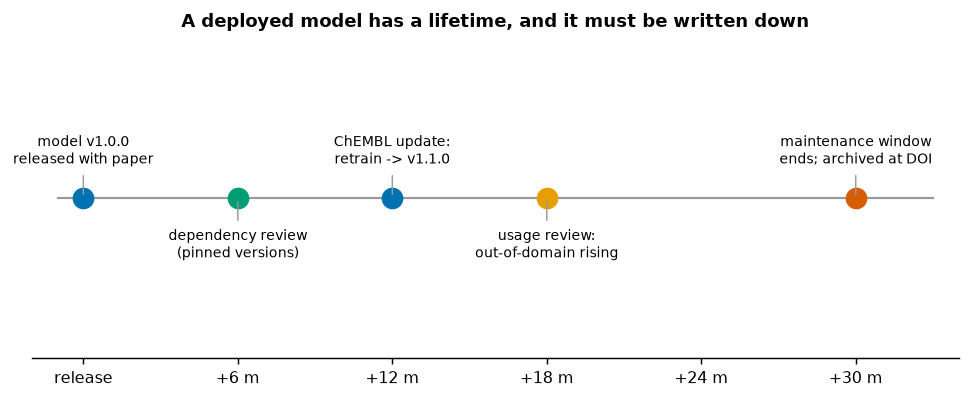

In [22]:
# The life of a deployed tool, with the obligations marked.
fig, ax = plt.subplots(figsize=(9.2, 3.2))
events = [(0, "model v1.0.0\nreleased with paper", "#0072B2"),
          (6, "dependency review\n(pinned versions)", "#009E73"),
          (12, "ChEMBL update:\nretrain -> v1.1.0", "#0072B2"),
          (18, "usage review:\nout-of-domain rising", "#E69F00"),
          (30, "maintenance window\nends; archived at DOI", "#D55E00")]
ax.plot([-1, 33], [0, 0], color="#999999", lw=1.2, zorder=0)
for month, label, colour in events:
    ax.plot(month, 0, "o", ms=11, color=colour, zorder=2)
    up = 1 if events.index((month, label, colour)) % 2 == 0 else -1
    ax.annotate(label, (month, 0), xytext=(0, 26 * up), textcoords="offset points",
                ha="center", va="center" if up > 0 else "center", fontsize=8,
                arrowprops=dict(arrowstyle="-", lw=0.8, color="#999999"))
ax.set_xlim(-2, 34); ax.set_ylim(-1.2, 1.2); ax.set_yticks([])
ax.set_xticks([0, 6, 12, 18, 24, 30], ["release", "+6 m", "+12 m", "+18 m", "+24 m", "+30 m"])
for spine in ("left", "right", "top"):
    ax.spines[spine].set_visible(False)
ax.set_title("A deployed model has a lifetime, and it must be written down")
plt.show()
print("the commitments in the model card are what make the last event an orderly retirement")
print("rather than a dead link in a published paper")

<p class="caption"><b>Figure 8.</b> The life cycle the group commits to when it deploys a model: release with the paper, a dependency review every six months, retraining when the source database changes materially, a usage review that watches the fraction of out-of-domain submissions, and an announced end of the maintenance window with the artefact archived under a DOI. The dates are a policy, not a prediction; what matters is that they exist in writing before the tool is published.</p>

<div class="exercise"><h4>Exercise 2</h4>
<p>Write the sunset paragraph for a tool your own project would deploy: how long it is maintained, who maintains it after the author graduates, what is archived and where, and what a user should do when the service stops. Then check the last three computational tools you used from a paper: how many are still running, and how many tell you what to do if they are not?</p></div>

## 11. Summary

**Shipping a model means shipping a contract**, not a file: a prediction, an interval with measured coverage, an applicability-domain verdict and evidence a chemist can judge. The same function serves the application and the API, which is what keeps the two consistent.

**Serialisation is not documentation.** `joblib.dump` stores an object graph with no record of the environment; a manifest with library versions, data checksums, metrics and licences turns it into an artefact, and a start-up environment check turns a silent incompatibility into a refusal<sup class="c"><a href="#r5">[5]</a></sup>. ONNX is the option when the model must leave the Python ecosystem.

**Validate before predicting.** Every rejection class — unparsable, inorganic, too large, too small, empty, a mixture — returns a reason rather than a number or a traceback, and the standardised structure is echoed back so the user sees what was actually scored.

**Silent extrapolation is the failure mode of deployment.** Asked about decoys and about molecules from chemistry it never saw — a sugar, a dye, a peptide fragment — the model returned confident-looking potencies clustered around its training mean, with a spread far narrower than for genuine test compounds, and the distance measure flagged every one of them while the prediction itself gave no sign. Within the scaffold test set the same measure barely graded the error at all: a domain flag is a filter on what may be asked, not a correction to the answer.

**Model cards and dataset cards are the instrument for that**<sup class="c"><a href="#r1">[1]</a><a href="#r2">[2]</a></sup>: intended and unintended uses, provenance and biases of the data, metrics under the honest split, the domain definition with its threshold, limitations, and a maintenance commitment — generated from the analysis, like everything else in Unit 23.

**Deployment creates obligations**: secrets from the environment, logs without chemistry, two version numbers, a health endpoint, a watch on the distribution of what users submit, and a written sunset policy with an archived artefact so that the paper outlives the server.

<div class="box bridge"><h4>Bridge</h4>
<p>The model served here was built in <a href="../U14_Ensembles_Tuning/index.html">Unit 14</a>, validated on the splits of <a href="../U12_Validation/index.html">Unit 12</a>, explained with the attributions of <a href="../U16_Interpretability/index.html">Unit 16</a>, and given its applicability domain and conformal intervals in <a href="../U17_Uncertainty_AD/index.html">Unit 17</a>; its data and their biases come from <a href="../U6_Data_Quality/index.html">Unit 6</a>, its reporting from <a href="../U23_Communication/index.html">Unit 23</a>, the package and tests behind <code>rockserve</code> from <a href="../U24_Software_Engineering/index.html">Unit 24</a>, and the container it is deployed in from <a href="../U25_Scaling_HPC/index.html">Unit 25</a>. <a href="../U27_Capstone/index.html">Unit 27</a> asks for a model card as part of the capstone deliverable. In the sister courses, <a href="../../Cheminformatics/U14_Validation/index.html">Validation</a> covers the QSAR reporting conventions a model card must satisfy, <a href="../../Cheminformatics/U5_Descriptors_Fingerprints/index.html">Descriptors and fingerprints</a> explains the representation whose bits appear in the attributions, and the AI course's <a href="../../BGM411/Python/S1_Model_Evaluation/index.html">Model evaluation</a> unit covers the metrics quoted in the card.</p></div>

## 12. Self-assessment

<details><summary>1. A collaborator asks for "the model". What do you send, and why is the file not enough?</summary>
<p>The model file, a manifest (library versions, data checksum, hyperparameters, metrics, split), the inference code including validation and the applicability-domain definition, and the model card. The file alone is a pickle whose behaviour depends on the scikit-learn version that loads it, which says nothing about what it was trained on, how well it does on new chemistry, or where it must not be used — and which executes code when opened.</p></details>

<details><summary>2. Why must the conformal quantile be computed on a calibration set rather than on the training residuals?</summary>
<p>Because a random forest fits its training data almost perfectly, so training residuals are far smaller than prediction errors on new compounds; intervals built from them would be far too narrow. The calibration set is data the model never saw during fitting, which is what makes the rank argument behind conformal validity apply. In the three-way split used here the calibration compounds also share no scaffold with the training compounds.</p></details>

<details><summary>3. Work out the conformal index for n = 199 calibration residuals at 95 % confidence, and say what happens at n = 15.</summary>
<p>k = ceil(200 x 0.95) = 190, so the half-width is the 190th smallest of the 199 residuals. At n = 15, ceil(16 x 0.95) = 16 > 15: the required index does not exist, so a 95 % interval cannot be formed. The rule is n >= 1/eps - 1, that is at least 19 calibration points for 95 %; with fewer, report a lower confidence and say so.</p></details>

<details><summary>4. The tool returns pActivity 6.4 for a sugar. Is the model broken?</summary>
<p>No - it is doing what regression models do. A random forest averages the training leaves its input falls into, so an unfamiliar molecule receives something close to the training mean, with no indication that the question was inappropriate. The defect is in the interface if it shows that number without the applicability-domain verdict; in Section 6 every one of the exotic molecules was flagged as outside the domain, and that flag — not the number — is the answer the user needs.</p></details>

<details><summary>5. Give three input classes your validation must reject and the message for each.</summary>
<p>An unparsable string ("not a parsable SMILES string" - a compound name is the usual cause); a molecule with unsupported elements ("unsupported elements: ['Pt']" - the training set is small organic molecules); and a structure outside the size window ("120 heavy atoms, outside the supported range 3-70"). A mixture or salt is a fourth class, handled differently: the largest fragment is kept and the user is told, because silently predicting for a different species is worse than refusing.</p></details>

<details><summary>6. Why does the app cache the model with <code>st.cache_resource</code> and not <code>st.cache_data</code>?</summary>
<p>Because Streamlit re-runs the whole script on every interaction, and the model is a large non-serialisable object shared across sessions - which is exactly what <code>cache_resource</code> is for. <code>cache_data</code> is for the results of computations keyed by serialisable inputs (a prediction for a given SMILES, say); using it for a model would try to copy the object per session.</p></details>

<details><summary>7. What does the pydantic request schema buy that a manual check does not?</summary>
<p>Validation before any of your code runs, a precise machine-readable error (HTTP 422 naming the offending field), an OpenAPI specification generated from the same declaration so clients can be generated automatically, and documentation that cannot drift from the implementation. The batch cap and the restricted confidence values are enforced in the same place they are documented.</p></details>

<details><summary>8. Which four tests would you write for the API, and what does each protect?</summary>
<p>A malformed payload returns 422 (the schema is active); a request without the key returns 401 when a key is configured (the secret is enforced, not merely present); an unparsable structure returns a 200 with <code>status: "rejected"</code> and a reason (one bad molecule does not fail a batch); and a reference molecule returns the same prediction to three decimals (a golden test protecting against an unnoticed model or dependency change).</p></details>

<details><summary>9. A user reports that the prediction for their compound changed between Monday and Friday. How do you diagnose it?</summary>
<p>Ask for the <code>model_version</code> from the response they kept, and compare with the current one from <code>/model</code>. If the versions differ, the model was retrained and the CHANGELOG says why. If they are the same, the environment changed under the service: compare the running library versions with the manifest - which is the check that should have refused to start - and look at the logs for a restart. This is why the version travels in every response.</p></details>

<details><summary>10. What belongs in the "not intended" section of a model card for this predictor?</summary>
<p>Absolute potency for decisions without experimental confirmation; selectivity against other kinases, which it was never trained on; anything clinical, diagnostic or safety-related; and prediction for molecules outside the stated applicability domain. The section exists because a model is used for whatever it plausibly answers, and the author is the only person who knows what it cannot do.</p></details>

<details><summary>11. Your free-tier Space has been asleep for three months and the paper is published. What should already be in place?</summary>
<p>An archived release of the repository and the model artefact with a DOI, cited in the paper instead of (or alongside) the URL; a README with local installation instructions; a stated maintenance window; and a named contact. The service going to sleep is then an inconvenience rather than a reproducibility failure - which is the practical content of a sunset policy.</p></details>

<details><summary>12. A colleague wants to score a 200,000-compound catalogue through your API. What do you tell them?</summary>
<p>Not through the API: at the per-compound latency measured in Section 1 of this unit's interface, that is many hours of requests, and the batch endpoint is capped at 200 structures for exactly that reason. Give them the package and the model artefact so they can run it locally or on the cluster with the parallelisation of Unit 25, and point out that most of those compounds will be outside the applicability domain, so the useful first step is to filter by distance to the training set before predicting anything.</p></details>

## Glossary

<dl class="gloss">
<dt>Applicability domain</dt><dd>The region of chemical space where a model's predictions are supported by training data; here, mean Tanimoto distance to the five nearest training compounds, with a threshold from the training distribution.</dd>
<dt>Conformal prediction (inductive)</dt><dd>A distribution-free method giving intervals with a stated coverage, built from the quantile of residuals on a held-out calibration set.</dd>
<dt>Dataset card / datasheet</dt><dd>A structured description of a data set: provenance, composition, collection process, biases, recommended and discouraged uses, licence.</dd>
<dt>FastAPI / pydantic</dt><dd>A Python web framework that derives request validation and an OpenAPI specification from type-annotated schema classes.</dd>
<dt>Health endpoint</dt><dd>A trivial route (<code>/health</code>) that a hosting platform or monitor polls to decide whether a service is alive.</dd>
<dt>joblib</dt><dd>The serialisation library used for scikit-learn objects; a pickle-based format that stores references to classes, executes code on load and carries no environment information.</dd>
<dt>Model card</dt><dd>A short structured document stating a model's intended and unintended uses, training data, metrics under a named evaluation, applicability domain, limitations and maintenance.</dd>
<dt>ONNX</dt><dd>An interchange format storing the computation graph rather than Python objects, so a model can be run without the library that trained it.</dd>
<dt>Pickle trap</dt><dd>The failure in which a serialised model loads under a different library version and behaves differently instead of failing loudly.</dd>
<dt>Silent extrapolation</dt><dd>A confident-looking prediction for an input outside the model's domain; detectable only by a domain check, never by the prediction itself.</dd>
<dt>Streamlit</dt><dd>A framework that renders a Python script as a web application, re-running the script on every interaction; expensive objects must be cached.</dd>
<dt>Sunset policy</dt><dd>The written commitment describing how long a deployed tool is maintained, what is archived, and what users should do when it stops.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Mitchell M, Wu S, Zaldivar A, et al. Model cards for model reporting. In: <em>Proc. Conf. on Fairness, Accountability, and Transparency (FAT*)</em>; 2019:220-229. <a href="https://doi.org/10.1145/3287560.3287596">doi:10.1145/3287560.3287596</a></li>
<li id="r2">Gebru T, Morgenstern J, Vecchione B, et al. Datasheets for datasets. <em>Commun ACM</em>. 2021;64(12):86-92. <a href="https://doi.org/10.1145/3458723">doi:10.1145/3458723</a></li>
<li id="r3">Abid A, Abdalla A, Abid A, Khan D, Alfozan A, Zou J. Gradio: hassle-free sharing and testing of ML models in the wild. <em>arXiv</em>. 2019:1906.02569. <a href="https://doi.org/10.48550/arXiv.1906.02569">doi:10.48550/arXiv.1906.02569</a></li>
<li id="r4">Paleyes A, Urma RG, Lawrence ND. Challenges in deploying machine learning: a survey of case studies. <em>ACM Comput Surv</em>. 2022;55(6):114. <a href="https://doi.org/10.1145/3533378">doi:10.1145/3533378</a></li>
<li id="r5">Haibe-Kains B, Adam GA, Hosny A, et al. Transparency and reproducibility in artificial intelligence. <em>Nature</em>. 2020;586:E14-E16. <a href="https://doi.org/10.1038/s41586-020-2766-y">doi:10.1038/s41586-020-2766-y</a></li>
<li id="r6">Heil BJ, Hoffman MM, Markowetz F, Lee SI, Greene CS, Hicks SC. Reproducibility standards for machine learning in the life sciences. <em>Nat Methods</em>. 2021;18:1132-1135. <a href="https://doi.org/10.1038/s41592-021-01256-7">doi:10.1038/s41592-021-01256-7</a></li>
<li id="r7">Artrith N, Butler KT, Coudert FX, et al. Best practices in machine learning for chemistry. <em>Nat Chem</em>. 2021;13:505-508. <a href="https://doi.org/10.1038/s41557-021-00716-z">doi:10.1038/s41557-021-00716-z</a></li>
<li id="r8">Walsh I, Fishman D, Garcia-Gasulla D, et al. DOME: recommendations for supervised machine learning validation in biology. <em>Nat Methods</em>. 2021;18:1122-1127. <a href="https://doi.org/10.1038/s41592-021-01205-4">doi:10.1038/s41592-021-01205-4</a></li>
<li id="r9">Bender A, Schneider N, Segler M, Walters WP, Engkvist O, Rodrigues T. Evaluation guidelines for machine learning tools in the chemical sciences. <em>Nat Rev Chem</em>. 2022;6:428-442. <a href="https://doi.org/10.1038/s41570-022-00391-9">doi:10.1038/s41570-022-00391-9</a></li>
<li id="r10">Tropsha A. Best practices for QSAR model development, validation, and exploitation. <em>Mol Inform</em>. 2010;29(6-7):476-488. <a href="https://doi.org/10.1002/minf.201000061">doi:10.1002/minf.201000061</a></li>
<li id="r11">Lundberg SM, Lee SI. A unified approach to interpreting model predictions. In: <em>NeurIPS 30</em>; 2017. <a href="https://doi.org/10.48550/arXiv.1705.07874">doi:10.48550/arXiv.1705.07874</a></li>
<li id="r12">Lundberg SM, Erion G, Chen H, et al. From local explanations to global understanding with explainable AI for trees. <em>Nat Mach Intell</em>. 2020;2:56-67. <a href="https://doi.org/10.1038/s42256-019-0138-9">doi:10.1038/s42256-019-0138-9</a></li>
<li id="r13">Jimenez-Luna J, Grisoni F, Schneider G. Drug discovery with explainable artificial intelligence. <em>Nat Mach Intell</em>. 2020;2:573-584. <a href="https://doi.org/10.1038/s42256-020-00236-4">doi:10.1038/s42256-020-00236-4</a></li>
<li id="r14">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL database in 2023. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180-D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r15">Norinder U, Carlsson L, Boyer S, Eklund M. Introducing conformal prediction in predictive modeling: a transparent and flexible alternative to applicability domain determination. <em>J Chem Inf Model</em>. 2014;54(6):1596-1603. <a href="https://doi.org/10.1021/ci5001168">doi:10.1021/ci5001168</a></li>
<li id="r16">Svensson F, Aniceto N, Norinder U, et al. Conformal regression for quantitative structure-activity relationship modeling - quantifying prediction uncertainty. <em>J Chem Inf Model</em>. 2018;58(5):1132-1140. <a href="https://doi.org/10.1021/acs.jcim.8b00054">doi:10.1021/acs.jcim.8b00054</a></li>
<li id="r17">Papadopoulos H, Proedrou K, Vovk V, Gammerman A. Inductive confidence machines for regression. In: <em>ECML 2002</em>. LNCS 2430. Springer; 2002:345-356. <a href="https://doi.org/10.1007/3-540-36755-1_29">doi:10.1007/3-540-36755-1_29</a></li>
<li id="r18">Vovk V, Gammerman A, Shafer G. <em>Algorithmic Learning in a Random World</em>. Springer; 2005. <a href="https://doi.org/10.1007/b106715">doi:10.1007/b106715</a></li>
<li id="r19">Sahigara F, Mansouri K, Ballabio D, Mauri A, Consonni V, Todeschini R. Comparison of different approaches to define the applicability domain of QSAR models. <em>Molecules</em>. 2012;17(5):4791-4810. <a href="https://doi.org/10.3390/molecules17054791">doi:10.3390/molecules17054791</a></li>
<li id="r20">Mervin LH, Johansson S, Semenova E, Giblin KA, Engkvist O. Uncertainty quantification in drug design. <em>Drug Discov Today</em>. 2021;26(2):474-489. <a href="https://doi.org/10.1016/j.drudis.2020.11.027">doi:10.1016/j.drudis.2020.11.027</a></li>
<li id="r21">Wallach I, Heifets A. Most ligand-based classification benchmarks reward memorization rather than generalization. <em>J Chem Inf Model</em>. 2018;58(5):916-932. <a href="https://doi.org/10.1021/acs.jcim.7b00403">doi:10.1021/acs.jcim.7b00403</a></li>
<li id="r22">Sheridan RP. Time-split cross-validation as a method for estimating the goodness of prospective prediction. <em>J Chem Inf Model</em>. 2013;53(4):783-790. <a href="https://doi.org/10.1021/ci400084k">doi:10.1021/ci400084k</a></li>
<li id="r23">Kramer C, Kalliokoski T, Gedeck P, Vulpetti A. The experimental uncertainty of heterogeneous public Ki data. <em>J Med Chem</em>. 2012;55(11):5165-5173. <a href="https://doi.org/10.1021/jm300131x">doi:10.1021/jm300131x</a></li>
<li id="r24">Breiman L. Random forests. <em>Mach Learn</em>. 2001;45:5-32. <a href="https://doi.org/10.1023/A:1010933404324">doi:10.1023/A:1010933404324</a></li>
<li id="r25">Pedregosa F, Varoquaux G, Gramfort A, et al. Scikit-learn: machine learning in Python. <em>J Mach Learn Res</em>. 2011;12:2825-2830. <a href="https://doi.org/10.48550/arXiv.1201.0490">doi:10.48550/arXiv.1201.0490</a></li>
<li id="r26">Chue Hong NP, Katz DS, Barker M, et al. Introducing the FAIR principles for research software. <em>Sci Data</em>. 2022;9:622. <a href="https://doi.org/10.1038/s41597-022-01710-x">doi:10.1038/s41597-022-01710-x</a></li>
<li id="r27">Smith AM, Katz DS, Niemeyer KE. Software citation principles. <em>PeerJ Comput Sci</em>. 2016;2:e86. <a href="https://doi.org/10.7717/peerj-cs.86">doi:10.7717/peerj-cs.86</a></li>
<li id="r28">Stokes JM, Yang K, Swanson K, et al. A deep learning approach to antibiotic discovery. <em>Cell</em>. 2020;180(4):688-702. <a href="https://doi.org/10.1016/j.cell.2020.01.021">doi:10.1016/j.cell.2020.01.021</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Huyen C. <em>Designing Machine Learning Systems</em>. O'Reilly; 2022. - Deployment, monitoring and the failure modes of models in production, written for practitioners.</li>
<li>Molnar C. <em>Interpretable Machine Learning</em>. 2nd ed.; 2022 (free online). - The attribution methods behind the explanation panel of the application.</li>
<li>Geron A. <em>Hands-On Machine Learning</em>. 3rd ed. O'Reilly; 2022. - Chapter 19 for serving models and the pitfalls of serialisation.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>Streamlit documentation, especially caching and <code>st.cache_resource</code>: <a href="https://docs.streamlit.io/">docs.streamlit.io</a>.</li>
<li>FastAPI documentation, including the tutorial on testing with <code>TestClient</code>: <a href="https://fastapi.tiangolo.com/">fastapi.tiangolo.com</a>.</li>
<li>Hugging Face Spaces and the Model Card guidebook: <a href="https://huggingface.co/docs/hub/spaces">huggingface.co/docs/hub/spaces</a>, <a href="https://huggingface.co/docs/hub/model-cards">huggingface.co/docs/hub/model-cards</a>.</li>
<li>ONNX and skl2onnx documentation: <a href="https://onnx.ai/">onnx.ai</a>, <a href="https://onnx.ai/sklearn-onnx/">onnx.ai/sklearn-onnx</a>.</li>
<li>scikit-learn, "Model persistence", on the security and compatibility of pickled estimators: <a href="https://scikit-learn.org/stable/model_persistence.html">scikit-learn.org</a>.</li>
</ul>

In [23]:
# Clean up: remove the artefacts this notebook wrote.
produced = sorted(p.name for p in WORK.iterdir())
print("artefacts written by this notebook:", produced)
shutil.rmtree(WORK, ignore_errors=True)
print("folder removed:", not WORK.exists())

artefacts written by this notebook: ['DATA_CARD.md', 'MODEL_CARD.md', 'api.py', 'app.py', 'manifest.json', 'rock1_rf_v1.0.0.joblib']
folder removed: True
